# DAF-DRP (BRICS) — chạy từ đầu, xem dữ liệu qua từng bước

Notebook này đi qua toàn bộ pipeline của `daf_drp_brics/` **chỉ dùng code có sẵn**
(`fragment_vocab.py`, `data.py`, `model.py`, `train.py` và package `fragdrp`), và
dừng lại ở mỗi bước để vẽ dữ liệu ra:

| Bước | Nội dung | Code dùng lại |
|---|---|---|
| 1 | Tải dữ liệu response + gene expression | `fragdrp.data.loader.load_response_data` |
| 2 | Chia fold LDO (leave-drug-out) | `fragdrp.data.splits.make_folds` |
| 3 | Một phân tử mẫu: SMILES → `Mol` | `fragment_vocab.decompose` |
| 4 | **Atom graph**: feature từng nguyên tử + cạnh | `fragdrp.chem.featurizer.atom_features` |
| 5 | **BRICS**: tìm liên kết cắt → mảnh thô → gộp mảnh nhỏ | `fragdrp.chem.fragmenters` |
| 6 | **Atom → Fragment**: ma trận gán, đồ thị mảnh (Eq. 1) | `Fragmentation.atom_to_fragment`, `junction_bonds` |
| 7 | Vocabulary BRICS + coverage | `fragment_vocab.build_vocabulary`, `coverage_report` |
| 8 | `DualGraph` (atom graph + fragment graph dạng index) | `data.featurize`, `build_drug_graphs` |
| 9 | Dataset, scaler, batching | `data.DualDataset`, `data.collate` |
| 10 | Mô hình: forward từng tầng, fusion, Eq. 6 | `model.DAFDRPBrics` |
| 11 | Huấn luyện 1 fold, log từng step | vòng lặp giống hệt `train.run_fold` |
| 12 | Đánh giá + so với baseline cell-line mean | `fragdrp.train.metrics.compute_metrics` |
| 13 | Nhìn vào embedding mảnh sau huấn luyện | — |
| 14 | Chạy tất cả fold | `train.run_fold` |

Mặc định dùng **TOYv1** (33 thuốc, chạy vài giây). Đổi `DATASET = "GDSC2"` ở ô cấu hình
để chạy dữ liệu thật (chậm hơn nhiều).

In [1]:
import copy
import io
import logging
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

HERE = Path.cwd() if (Path.cwd() / "model.py").exists() else Path.cwd() / "daf_drp_brics"
ROOT = HERE.parent
for p in (str(HERE), str(ROOT / "src")):
    if p not in sys.path:
        sys.path.insert(0, p)

import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, BRICS, Draw
from rdkit.Chem.Draw import rdMolDraw2D

# --- code có sẵn trong daf_drp_brics/ ---
from fragment_vocab import OOV_INDEX, build_vocabulary, coverage_report, decompose, fragment_smiles_of
from data import ATOM_DIM, DualDataset, build_drug_graphs, collate, featurize
from model import CrossAttentionFusion, DAFDRPBrics, WeightedAdditionFusion
from train import load_config, make_loader, run_fold

# --- code có sẵn trong fragdrp ---
from fragdrp.config import DataConfig, FragmenterConfig
from fragdrp.chem import functional_groups as fg
from fragdrp.chem.featurizer import (ATOM_SYMBOLS, CHIRAL_TAGS, DEGREES, FORMAL_CHARGES,
                                     HYBRIDISATIONS, NUM_HS, atom_features)
from fragdrp.chem.fragmenters import _acyclic_only, _brics_bonds, _build_fragmentation, fragment_molecule
from fragdrp.data.dataset import ResponseScaler, StandardScaler
from fragdrp.data.loader import drug_names, load_response_data
from fragdrp.data.splits import make_folds
from fragdrp.train.metrics import compute_metrics, format_metrics, primary_metric
from fragdrp.train.trainer import resolve_device, set_seed
from fragdrp.eval.molecule_plots import FRAGMENT_COLOURS, render_fragmentation
from fragdrp.eval.plots import AQUA, BLUE, GRID, INK, MUTED, NEUTRAL, ORANGE, apply_style

# fragdrp.eval.* gọi matplotlib.use("Agg") khi import -> bật lại inline sau khi import xong.
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

apply_style()
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(message)s",
                    datefmt="%H:%M:%S", stream=sys.stdout, force=True)
for noisy in ("fragdrp.data.splits", "matplotlib", "matplotlib.font_manager", "PIL"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

CRIT = "#e34948"            # màu cho liên kết bị cắt
SEQ = "Blues"               # colormap tuần tự (một hue) cho độ lớn
ONEHOT = ListedColormap(["white", BLUE])


def show_png(png: bytes, ax=None, title: str = ""):
    ax = ax or plt.gca()
    ax.imshow(plt.imread(io.BytesIO(png), format="png"))
    ax.axis("off")
    if title:
        ax.set_title(title, loc="left")
    return ax


def mol_png(mol, w=560, h=400, atom_indices=False, atoms=None, atom_colors=None,
            bonds=None, bond_colors=None):
    # Vẽ phân tử bằng tọa độ 2D có sẵn trong mol (để mọi hình dùng chung một bố cục).
    drawer = rdMolDraw2D.MolDraw2DCairo(w, h)
    opt = drawer.drawOptions()
    opt.addAtomIndices = atom_indices
    opt.addStereoAnnotation = False
    opt.bondLineWidth = 2
    opt.highlightBondWidthMultiplier = 14
    opt.fillHighlights = True
    rdMolDraw2D.PrepareAndDrawMolecule(
        drawer, Chem.Mol(mol),
        highlightAtoms=atoms or [], highlightAtomColors=atom_colors or {},
        highlightBonds=bonds or [], highlightBondColors=bond_colors or {},
    )
    drawer.FinishDrawing()
    return drawer.GetDrawingText()


def rgb(hex_colour, lighten=0.45):
    h = hex_colour.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) / 255 for i in (0, 2, 4))
    return (1 - lighten * (1 - r), 1 - lighten * (1 - g), 1 - lighten * (1 - b))


def frag_colour(k):
    return FRAGMENT_COLOURS[k % len(FRAGMENT_COLOURS)]


print("HERE =", HERE)
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())

HERE = E:\DRP\daf_drp_brics
torch 2.6.0+cu124 | CUDA: True


## 0. Cấu hình

`config.yaml` giữ nguyên các siêu tham số của Table 1 trong bài báo. Ở đây chỉ ghi đè
tên dataset, đường dẫn dữ liệu, và (với TOYv1) các ngưỡng lọc nhỏ hơn — giống hệt
cấu hình đã dùng cho `results/dafbrics_WA_TOYv1_LDO`.

In [2]:
DATASET = "TOYv1"      # "GDSC2" cho thực nghiệm thật
FOLD = 0               # fold dùng để minh hoạ huấn luyện ở bước 11
EXAMPLE_DRUG = None    # pubchem id của phân tử mẫu; None = tự chọn

cfg = load_config(HERE / "config.yaml")
cfg["data"]["dataset_name"] = DATASET
cfg["data"]["path_data"] = str(ROOT / "data")
if DATASET == "TOYv1":
    cfg["data"].update(min_pairs_per_drug=10, min_pairs_per_cell_line=3, gene_subset=None)

print(pd.DataFrame(
    [(sec, k, v) for sec in ("model", "fragmenter", "train", "data") for k, v in cfg[sec].items()],
    columns=["section", "key", "value"],
).to_string(index=False))

   section                      key           value
     model                      dim             128
     model              atom_layers               5
     model              frag_layers               5
     model               vocab_size             798
     model                 cell_dim             128
     model                  dropout             0.2
     model                head_dims            [64]
     model              drug_fusion               W
     model            global_fusion               A
     model fix_degenerate_attention           False
fragmenter                   method           brics
fragmenter            max_fragments              32
fragmenter       min_fragment_atoms               2
fragmenter          min_vocab_count               1
fragmenter             vocab_source             all
     train                optimizer            adam
     train                       lr          0.0001
     train               batch_size             256
     train  

## 1. Dữ liệu response và gene expression

`load_response_data` ghép bảng response (LN_IC50) với SMILES và vector biểu hiện gen
của cell line, rồi lọc bỏ thuốc/cell line có quá ít phép đo. Mỗi hàng là một cặp
(drug, cell line).

In [3]:
data_cfg = DataConfig(**cfg["data"])
data = load_response_data(data_cfg)
names = drug_names(data_cfg.path_data, DATASET)
frame = data.to_dataframe()
print(data.summary())
frame.head()

11:00:27 | Loading TOYv1 from E:\DRP\data


11:00:32 | Kept 1669/1776 responses with both drug and cell-line features


11:00:32 | TOYv1: 1,658 responses | 33 drugs | 87 cell lines | 13 genes | response mean 1.199 sd 2.592


TOYv1: 1,658 responses | 33 drugs | 87 cell lines | 13 genes | response mean 1.199 sd 2.592


,cell_line_id,drug_id,tissue,response
0,Ku812,6914657,Blood,-6.377174
1,BHT-101,6914657,Thyroid,-1.463009
2,Daoy,6914657,Brain,-3.534269
3,KE-37,6914657,Blood,-7.077933
4,KU-19-19,6914657,Bladder,-4.990300


11:00:32 | findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


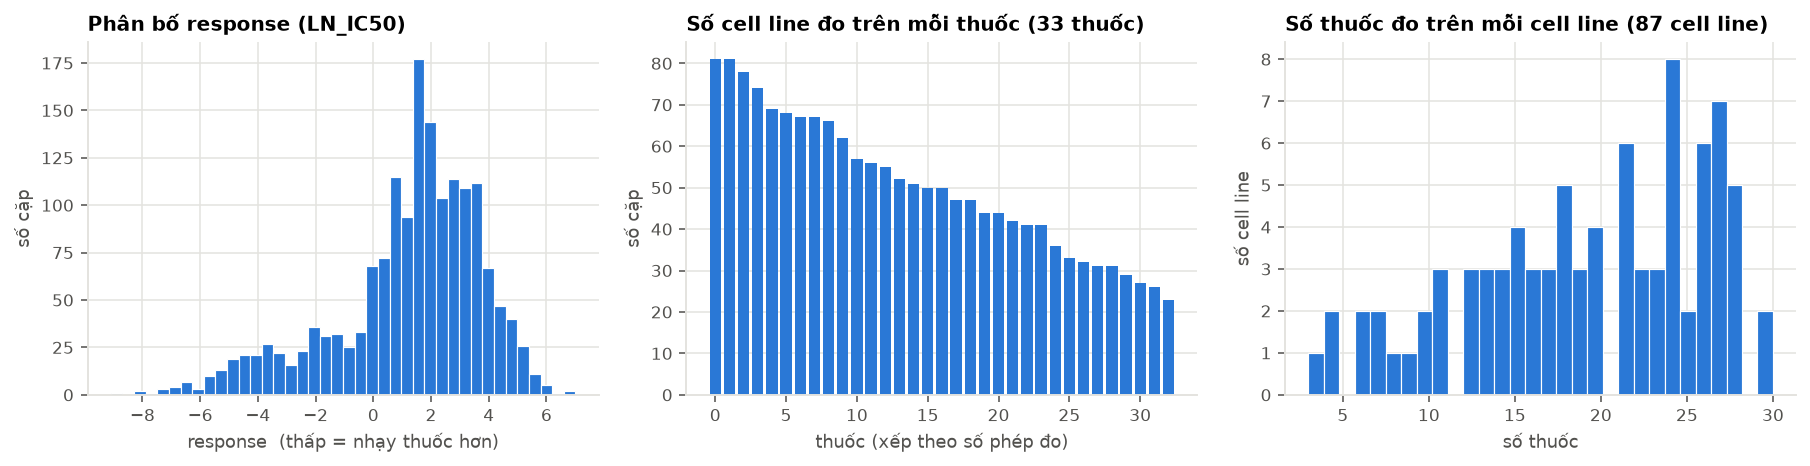

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

ax = axes[0]
ax.hist(frame["response"], bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_title("Phân bố response (LN_IC50)", loc="left")
ax.set_xlabel("response  (thấp = nhạy thuốc hơn)")
ax.set_ylabel("số cặp")

ax = axes[1]
per_drug = frame["drug_id"].value_counts()
ax.bar(range(len(per_drug)), per_drug.values, color=BLUE, width=0.8)
ax.set_title(f"Số cell line đo trên mỗi thuốc ({len(per_drug)} thuốc)", loc="left")
ax.set_xlabel("thuốc (xếp theo số phép đo)")
ax.set_ylabel("số cặp")

ax = axes[2]
per_cell = frame["cell_line_id"].value_counts()
ax.hist(per_cell.values, bins=30, color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_title(f"Số thuốc đo trên mỗi cell line ({len(per_cell)} cell line)", loc="left")
ax.set_xlabel("số thuốc")
ax.set_ylabel("số cell line")
plt.tight_layout()
plt.show()

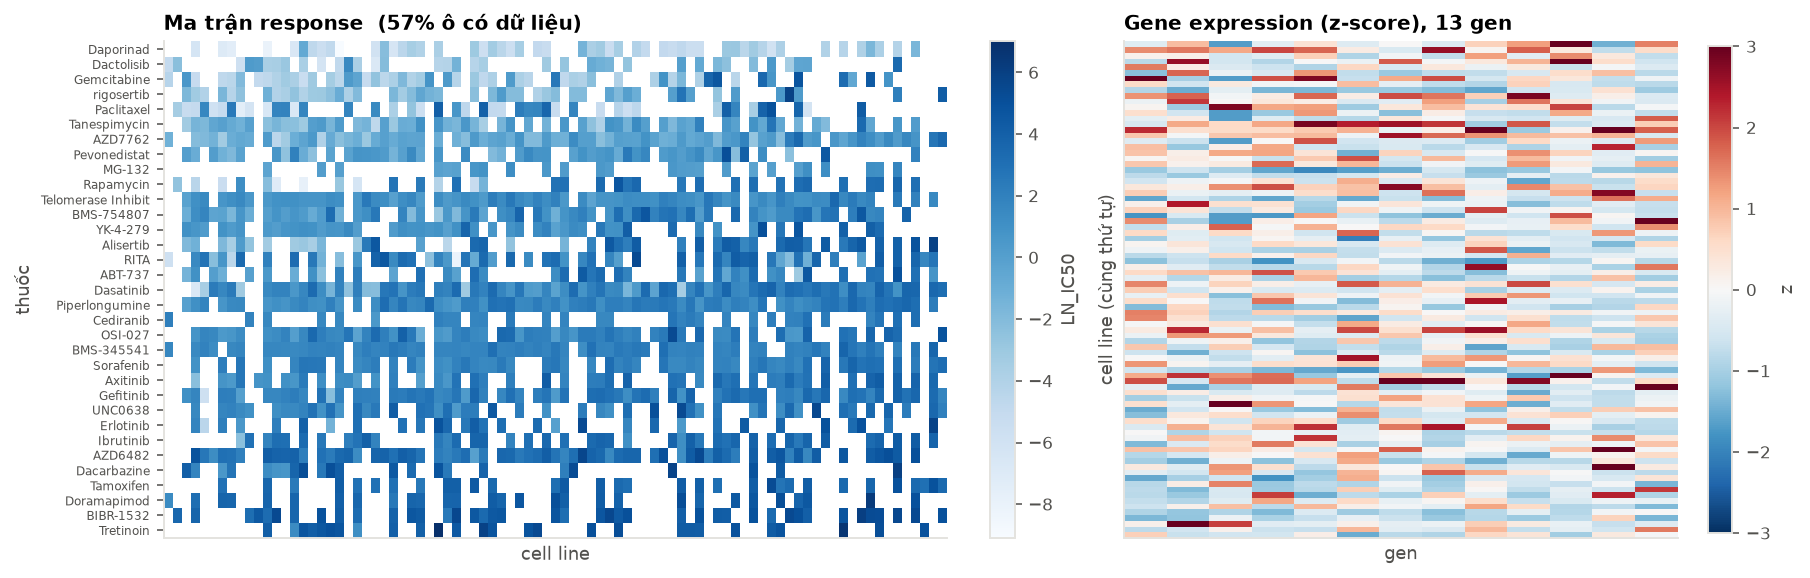

In [5]:
# Ma trận drug x cell line: ô trống = chưa đo.  Thuốc được sắp theo response trung bình.
matrix = frame.pivot_table(index="drug_id", columns="cell_line_id", values="response")
matrix = matrix.loc[matrix.mean(axis=1).sort_values().index]
matrix = matrix[matrix.mean(axis=0).sort_values().index]

genes = np.stack([data.cell_line_features[c] for c in matrix.columns])
z = (genes - genes.mean(0)) / (genes.std(0) + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
im = ax.imshow(matrix.values, aspect="auto", cmap=SEQ, interpolation="nearest")
ax.set_title(f"Ma trận response  ({matrix.notna().mean().mean():.0%} ô có dữ liệu)", loc="left")
ax.set_xlabel("cell line"); ax.set_ylabel("thuốc")
ax.set_yticks(range(len(matrix)))
ax.set_yticklabels([names.get(d, d)[:18] for d in matrix.index], fontsize=6)
ax.set_xticks([]); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03, label="LN_IC50")

ax = axes[1]
show = z[:, : min(z.shape[1], 60)]
im = ax.imshow(show, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
ax.set_title(f"Gene expression (z-score), {data.n_genes} gen", loc="left")
ax.set_xlabel("gen"); ax.set_ylabel("cell line (cùng thứ tự)")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label="z")
plt.tight_layout()
plt.show()

## 2. Chia fold — LDO (leave-drug-out)

Dưới LDO, **thuốc ở tập test không bao giờ xuất hiện khi train**. Đây là điều kiện để
biểu diễn phân tử (atom/fragment) thực sự phải mang thông tin: mô hình không thể học
thuộc "trung bình của thuốc này".

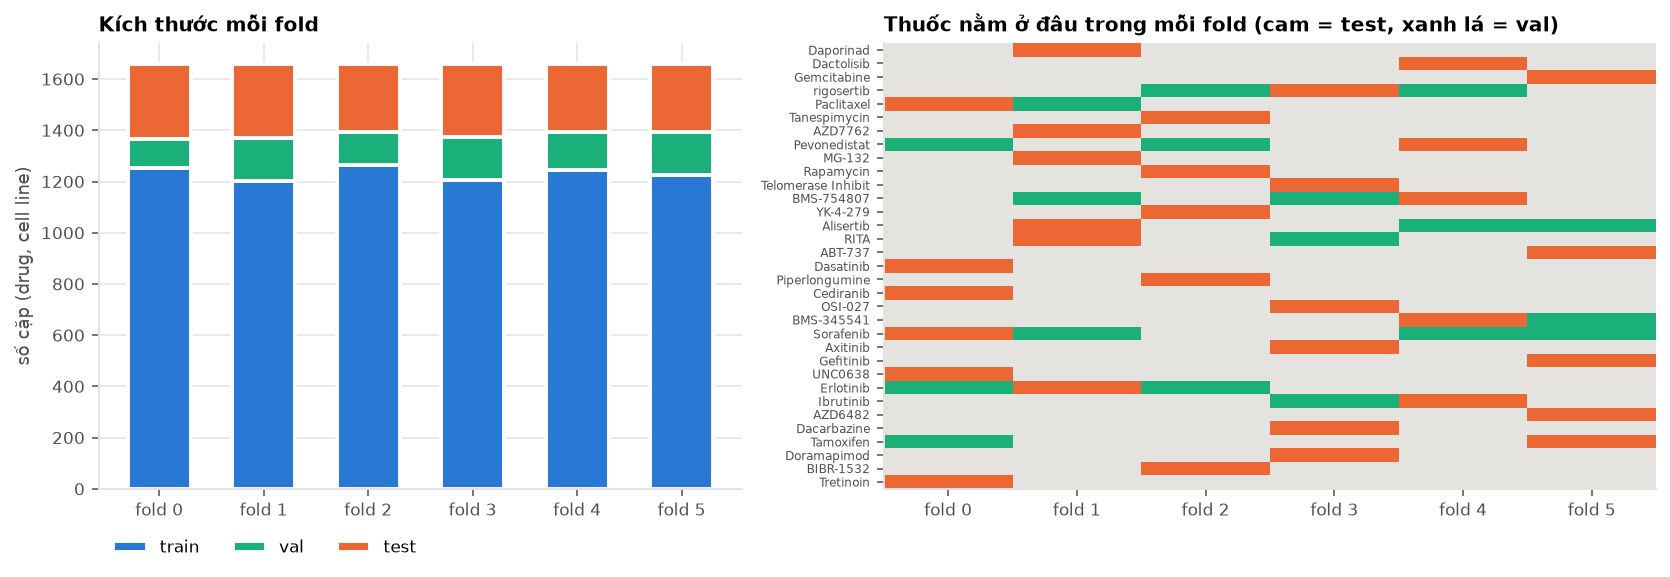

fold 0: train 1,253 | val 115 | test 290 | thuốc test cũng có trong train: 0
fold 1: train 1,201 | val 168 | test 289 | thuốc test cũng có trong train: 0
fold 2: train 1,264 | val 130 | test 264 | thuốc test cũng có trong train: 0
fold 3: train 1,207 | val 165 | test 286 | thuốc test cũng có trong train: 0
fold 4: train 1,244 | val 148 | test 266 | thuốc test cũng có trong train: 0
fold 5: train 1,225 | val 170 | test 263 | thuốc test cũng có trong train: 0


In [6]:
folds = make_folds(data, data_cfg, seed=int(cfg["train"]["seed"]))
drugs_sorted = list(matrix.index)
role = np.zeros((len(drugs_sorted), len(folds)))   # 0 train, 1 val, 2 test
for f in folds:
    for code_, rows in ((1, f.validation), (2, f.test)):
        for d in set(data.drug_ids[rows]):
            role[drugs_sorted.index(d), f.index] = code_

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
x = np.arange(len(folds))
sizes = np.array([[len(f.train), len(f.validation), len(f.test)] for f in folds])
bottom = np.zeros(len(folds))
for j, (lab, col) in enumerate(zip(["train", "val", "test"], [BLUE, AQUA, ORANGE])):
    ax.bar(x, sizes[:, j], bottom=bottom, color=col, label=lab, width=0.6,
           edgecolor="white", linewidth=2)
    bottom += sizes[:, j]
ax.set_xticks(x, [f"fold {i}" for i in x])
ax.set_ylabel("số cặp (drug, cell line)")
ax.set_title("Kích thước mỗi fold", loc="left")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.08))

ax = axes[1]
ax.imshow(role, aspect="auto", cmap=ListedColormap([GRID, AQUA, ORANGE]), vmin=0, vmax=2,
          interpolation="nearest")
ax.set_title("Thuốc nằm ở đâu trong mỗi fold (cam = test, xanh lá = val)", loc="left")
ax.set_xticks(x, [f"fold {i}" for i in x])
ax.set_yticks(range(len(drugs_sorted)))
ax.set_yticklabels([names.get(d, d)[:18] for d in drugs_sorted], fontsize=6)
ax.grid(False)
plt.tight_layout()
plt.show()

for f in folds:
    tr, te = set(data.drug_ids[f.train]), set(data.drug_ids[f.test])
    print(f.sizes(), "| thuốc test cũng có trong train:", len(tr & te))

## 3. Một phân tử mẫu: SMILES → `Mol`

`fragment_vocab.decompose` parse SMILES, bỏ counter-ion (`strip_salts` giữ thành phần
liên thông lớn nhất), rồi phân mảnh. Ta lấy `mol` ra và gán sẵn tọa độ 2D để mọi hình
phía sau dùng chung một bố cục.

rigosertib  (pubchem 6918736)
SMILES : COC1=C(C=C(C=C1)CS(=O)(=O)C=CC2=C(C=C(C=C2OC)OC)OC)NCC(=O)O
31 nguyên tử nặng, 32 liên kết, 2 vòng


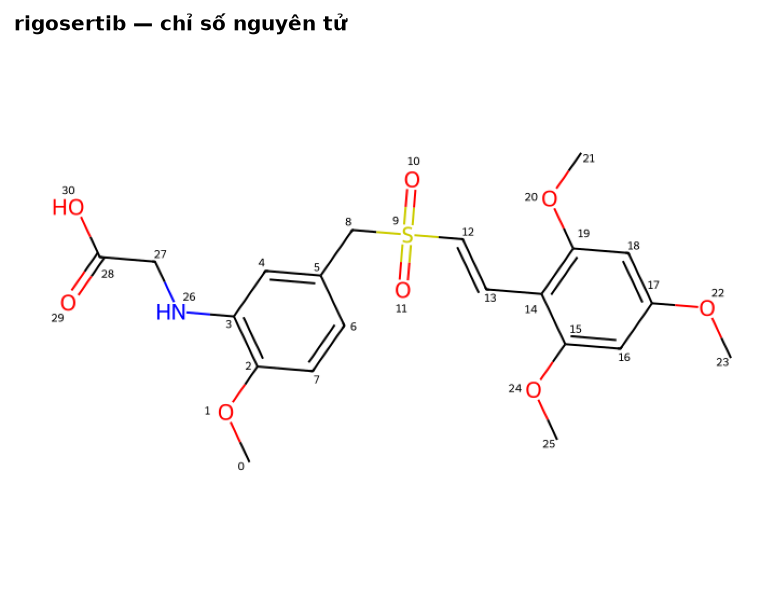

In [7]:
frag_cfg = FragmenterConfig(
    method=cfg["fragmenter"]["method"],
    max_fragments=int(cfg["fragmenter"]["max_fragments"]),
    min_fragment_atoms=int(cfg["fragmenter"]["min_fragment_atoms"]),
)

if EXAMPLE_DRUG is None:
    # Chọn thuốc có nhiều mảnh BRICS nhất trong khoảng 25-45 nguyên tử (dễ nhìn).
    def n_frags(smi):
        out = decompose(smi, frag_cfg)
        return -1 if out is None else out[1].n_fragments
    candidates = [(n_frags(s), d) for d, s in data.smiles.items()
                  if 25 <= Chem.MolFromSmiles(s).GetNumAtoms() <= 45]
    EXAMPLE_DRUG = max(candidates)[1] if candidates else next(iter(data.smiles))

smiles = data.smiles[EXAMPLE_DRUG]
mol, fragmentation = decompose(smiles, frag_cfg)
AllChem.Compute2DCoords(mol)
coords = np.array([[p.x, p.y] for p in (mol.GetConformer().GetAtomPosition(i)
                                        for i in range(mol.GetNumAtoms()))])
name = names.get(EXAMPLE_DRUG, EXAMPLE_DRUG)
print(f"{name}  (pubchem {EXAMPLE_DRUG})")
print("SMILES :", smiles)
print(f"{mol.GetNumAtoms()} nguyên tử nặng, {mol.GetNumBonds()} liên kết, "
      f"{mol.GetRingInfo().NumRings()} vòng")

plt.figure(figsize=(7, 5))
show_png(mol_png(mol, 700, 500, atom_indices=True), title=f"{name} — chỉ số nguyên tử")
plt.show()

## 4. View 1 — Atom graph

Mỗi nguyên tử là một node với vector feature one-hot (`atom_features`), mỗi liên kết là
hai cạnh có hướng. DAF-DRP dùng GIN thuần nên **không có edge feature**.

atom_x : (31, 49)  | adjacency : (31, 31)  | edge_index: (2, 64 )


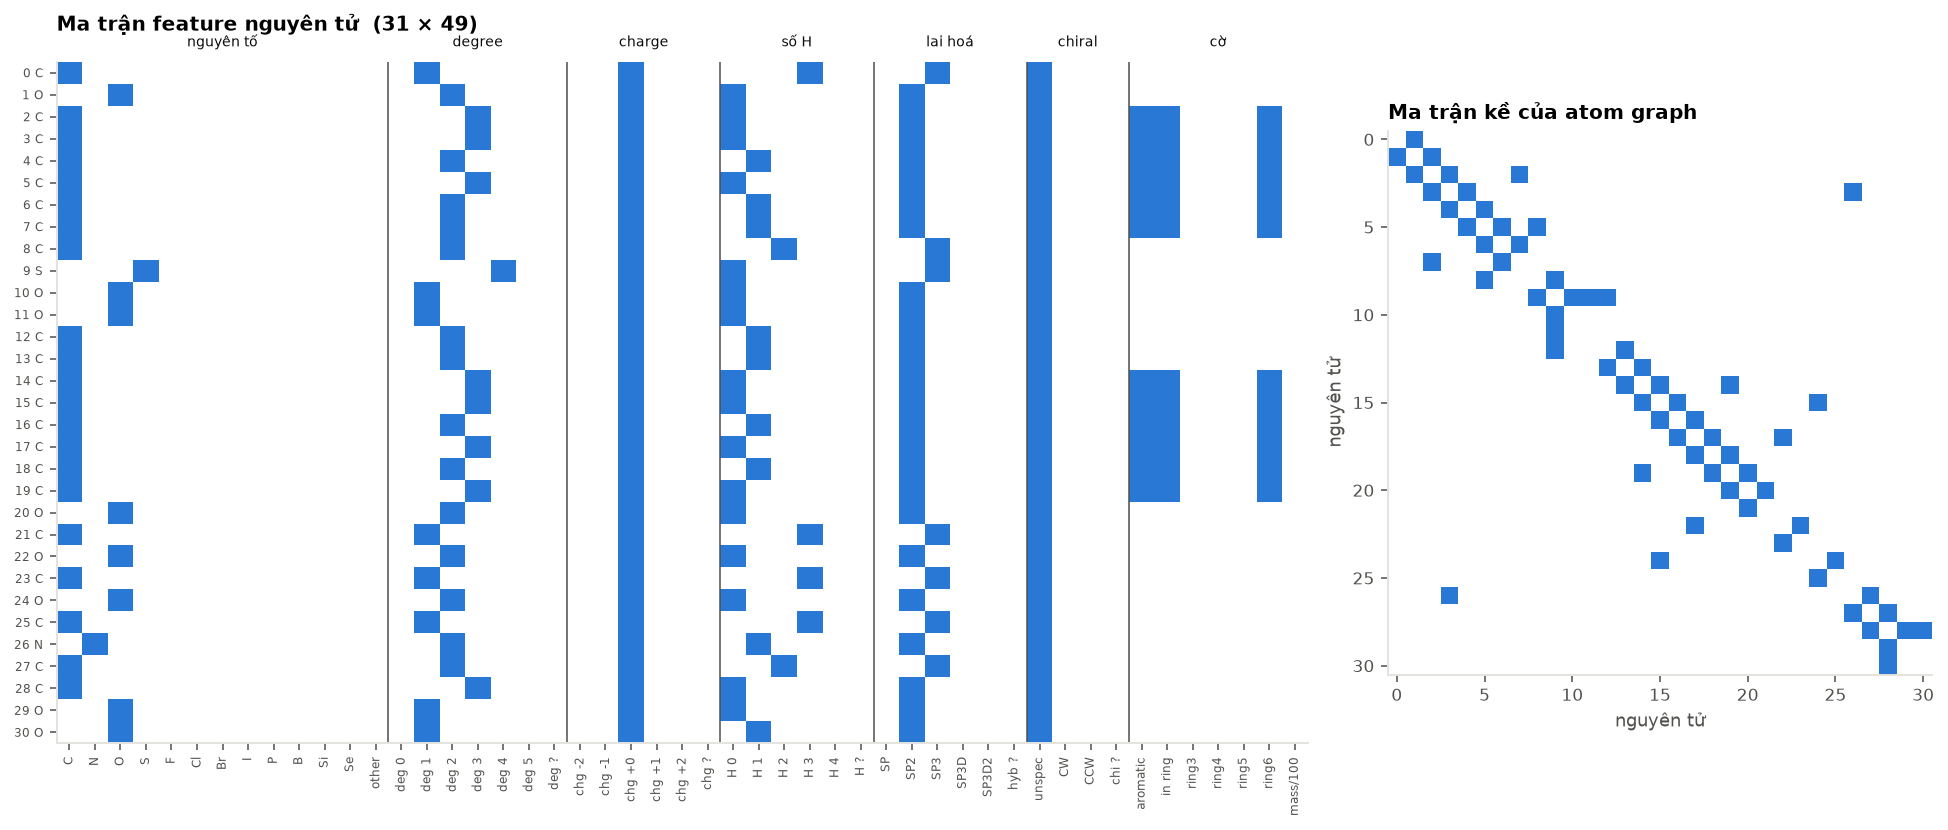

In [8]:
FEATURE_GROUPS = [
    ("nguyên tố", list(ATOM_SYMBOLS)),
    ("degree", [f"deg {d}" for d in DEGREES] + ["deg ?"]),
    ("charge", [f"chg {c:+d}" for c in FORMAL_CHARGES] + ["chg ?"]),
    ("số H", [f"H {h}" for h in NUM_HS] + ["H ?"]),
    ("lai hoá", [str(h).split(".")[-1] for h in HYBRIDISATIONS] + ["hyb ?"]),
    ("chiral", ["unspec", "CW", "CCW", "chi ?"]),
    ("cờ", ["aromatic", "in ring", "ring3", "ring4", "ring5", "ring6", "mass/100"]),
]
feature_names = [n for _g, ns in FEATURE_GROUPS for n in ns]
assert len(feature_names) == ATOM_DIM, (len(feature_names), ATOM_DIM)

atom_x = np.asarray([atom_features(a) for a in mol.GetAtoms()], dtype=np.float32)
A = Chem.GetAdjacencyMatrix(mol)
print("atom_x :", atom_x.shape, " | adjacency :", A.shape, " | edge_index: (2,", 2 * mol.GetNumBonds(), ")")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2.3, 1]})
ax = axes[0]
ax.imshow(np.clip(atom_x, 0, 1), aspect="auto", cmap=ONEHOT, interpolation="nearest")
ax.set_xticks(range(ATOM_DIM), feature_names, rotation=90, fontsize=6)
ax.set_yticks(range(len(atom_x)),
              [f"{a.GetIdx()} {a.GetSymbol()}" for a in mol.GetAtoms()], fontsize=6)
start = 0
for g, ns in FEATURE_GROUPS:
    ax.axvline(start - 0.5, color=MUTED, lw=0.8)
    ax.text(start + len(ns) / 2 - 0.5, -1.2, g, ha="center", fontsize=7, color=INK)
    start += len(ns)
ax.grid(False)
ax.set_title(f"Ma trận feature nguyên tử  ({len(atom_x)} × {ATOM_DIM})", loc="left", pad=16)

ax = axes[1]
ax.imshow(A, cmap=ONEHOT, interpolation="nearest")
ax.set_title("Ma trận kề của atom graph", loc="left")
ax.set_xlabel("nguyên tử"); ax.set_ylabel("nguyên tử"); ax.grid(False)
plt.tight_layout()
plt.show()

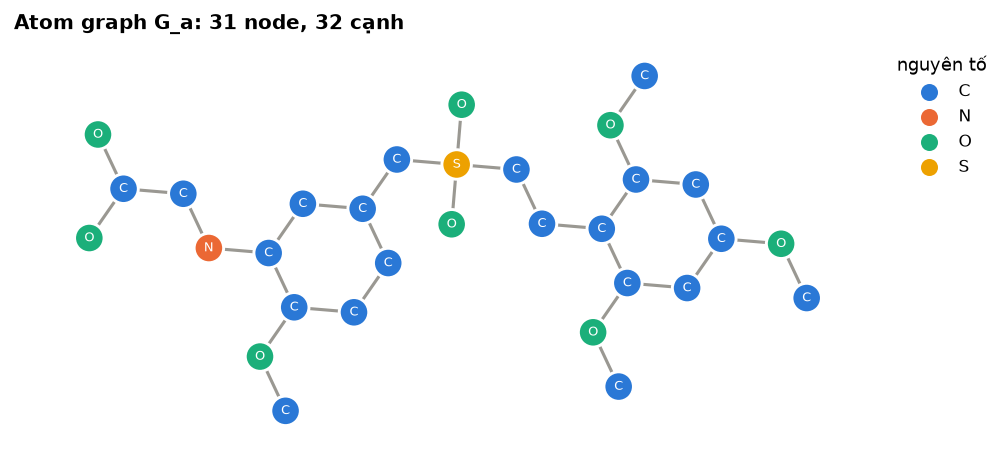

In [9]:
G_atom = nx.from_numpy_array(A)
pos = {i: coords[i] for i in range(len(coords))}
elements = sorted({a.GetSymbol() for a in mol.GetAtoms()}, key=lambda s: (s != "C", s))
elem_colour = {e: FRAGMENT_COLOURS[i % len(FRAGMENT_COLOURS)] for i, e in enumerate(elements)}

fig, ax = plt.subplots(figsize=(8, 5.5))
nx.draw_networkx_edges(G_atom, pos, ax=ax, edge_color=NEUTRAL, width=1.6)
nx.draw_networkx_nodes(G_atom, pos, ax=ax, node_size=230, edgecolors="white", linewidths=1.5,
                       node_color=[elem_colour[mol.GetAtomWithIdx(i).GetSymbol()] for i in G_atom])
nx.draw_networkx_labels(G_atom, pos, ax=ax, font_size=6.5, font_color="white",
                        labels={i: mol.GetAtomWithIdx(i).GetSymbol() for i in G_atom})
for e, c in elem_colour.items():
    ax.scatter([], [], color=c, s=60, label=e)
ax.legend(title="nguyên tố", loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title(f"Atom graph G_a: {G_atom.number_of_nodes()} node, {G_atom.number_of_edges()} cạnh",
             loc="left")
ax.set_aspect("equal"); ax.axis("off")
plt.show()

## 5. BRICS — từng bước từ liên kết cắt đến mảnh

`fragment_molecule` làm ba việc:

1. **Tìm liên kết cắt** theo 16 luật retrosynthesis của BRICS (`BRICS.FindBRICSBonds`);
2. **Bỏ liên kết trong vòng** (`_acyclic_only`) để không phá vòng;
3. Lấy các **thành phần liên thông** sau khi cắt, rồi **gộp mảnh quá nhỏ**
   (`min_fragment_atoms`) vào mảnh hàng xóm lớn nhất, và gộp tiếp nếu vượt `max_fragments`.

Ô dưới tái hiện từng bước bằng chính các hàm nội bộ đó.

In [10]:
raw = list(BRICS.FindBRICSBonds(mol))
brics_table = pd.DataFrame([
    {"atom_i": i, "atom_j": j, "cặp": f"{mol.GetAtomWithIdx(i).GetSymbol()}{i}–"
                                        f"{mol.GetAtomWithIdx(j).GetSymbol()}{j}",
     "nhãn BRICS": f"{li} / {lj}",
     "trong vòng": mol.GetBondBetweenAtoms(i, j).IsInRing()}
    for (i, j), (li, lj) in raw
])
cut = _acyclic_only(mol, _brics_bonds(mol))
print(f"BRICS tìm thấy {len(raw)} liên kết cắt; giữ {len(cut)} liên kết ngoài vòng")
brics_table

BRICS tìm thấy 7 liên kết cắt; giữ 7 liên kết ngoài vòng


,atom_i,atom_j,cặp,nhãn BRICS,trong vòng
0,1,2,O1–C2,3 / 16,False
1,20,19,O20–C19,3 / 16,False
2,22,17,O22–C17,3 / 16,False
3,24,15,O24–C15,3 / 16,False
4,27,26,C27–N26,4 / 5,False
5,26,3,N26–C3,5 / 16,False
6,8,5,C8–C5,8 / 16,False


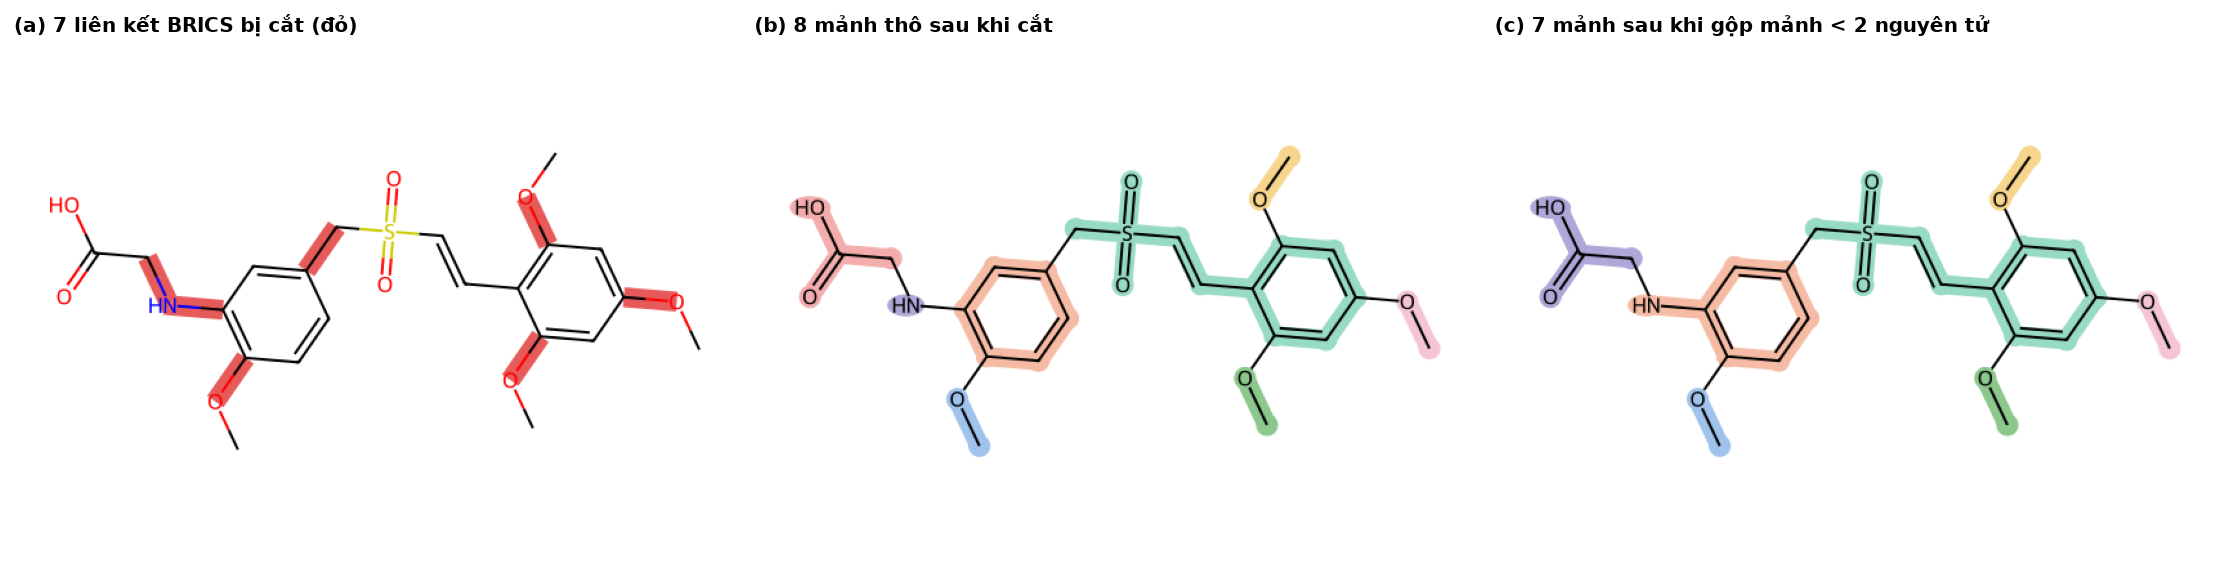

kích thước mảnh thô : [12, 6, 4, 2, 2, 2, 2, 1]
kích thước mảnh cuối: [12, 7, 4, 2, 2, 2, 2]


In [11]:
# (b) các mảnh thô: không gộp gì cả (min_fragment_atoms=1, max_fragments rất lớn)
raw_cfg = FragmenterConfig(method="brics", min_fragment_atoms=1, max_fragments=10_000)
raw_frag = _build_fragmentation(mol, cut, raw_cfg, "brics")
# (c) mảnh cuối cùng với cấu hình thật — phải trùng với fragment_molecule
final_frag = _build_fragmentation(mol, cut, frag_cfg, "brics")
assert final_frag.fragments == fragment_molecule(mol, frag_cfg, mol_key=smiles).fragments


def fragmentation_png(frag, w=560, h=400):
    atom_cols = {a: rgb(frag_colour(k)) for k, atoms in enumerate(frag.fragments) for a in atoms}
    bonds, bond_cols = [], {}
    for b in mol.GetBonds():
        ki = frag.atom_to_fragment[b.GetBeginAtomIdx()]
        if ki == frag.atom_to_fragment[b.GetEndAtomIdx()]:
            bonds.append(b.GetIdx()); bond_cols[b.GetIdx()] = rgb(frag_colour(ki))
    return mol_png(mol, w, h, atoms=list(atom_cols), atom_colors=atom_cols,
                   bonds=bonds, bond_colors=bond_cols)


cut_idx = [mol.GetBondBetweenAtoms(i, j).GetIdx() for i, j in cut]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
show_png(mol_png(mol, bonds=cut_idx, bond_colors={b: rgb(CRIT, 0.9) for b in cut_idx}),
         axes[0], f"(a) {len(cut)} liên kết BRICS bị cắt (đỏ)")
show_png(fragmentation_png(raw_frag), axes[1],
         f"(b) {raw_frag.n_fragments} mảnh thô sau khi cắt")
show_png(fragmentation_png(final_frag), axes[2],
         f"(c) {final_frag.n_fragments} mảnh sau khi gộp mảnh < {frag_cfg.min_fragment_atoms} nguyên tử")
plt.tight_layout()
plt.show()

sizes_raw = sorted((len(f) for f in raw_frag.fragments), reverse=True)
sizes_final = sorted((len(f) for f in final_frag.fragments), reverse=True)
print("kích thước mảnh thô :", sizes_raw)
print("kích thước mảnh cuối:", sizes_final)

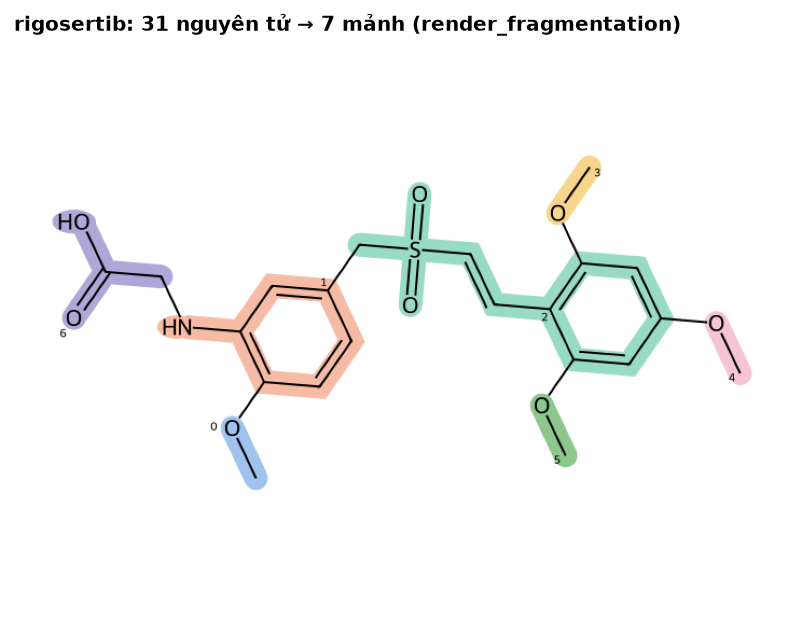

,mảnh,SMILES,số nguyên tử,nguyên tử,nhóm chức
0,0,CO,2,"[0, 1]",hydroxyl
1,1,Nc1ccccc1,7,"[2, 3, 4, 5, 6, 7, 26]","benzene, aniline"
2,2,CS(=O)(=O)C=Cc1ccccc1,12,"[8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]","sulfone, benzene"
3,3,CO,2,"[20, 21]",hydroxyl
4,4,CO,2,"[22, 23]",hydroxyl
5,5,CO,2,"[24, 25]",hydroxyl
6,6,CC(=O)O,4,"[27, 28, 29, 30]",carboxylic_acid


In [12]:
# Hình có sẵn của repo (render_fragmentation) — số trên cấu trúc là chỉ số mảnh.
frag_smiles = fragment_smiles_of(mol, fragmentation)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
show_png(render_fragmentation(Chem.Mol(mol), fragmentation, 720, 520), ax,
         f"{name}: {mol.GetNumAtoms()} nguyên tử → {fragmentation.n_fragments} mảnh (render_fragmentation)")
plt.show()

rows = []
for k, atoms in enumerate(fragmentation.fragments):
    sub = Chem.MolFromSmiles(frag_smiles[k])
    rows.append({"mảnh": k, "SMILES": frag_smiles[k], "số nguyên tử": len(atoms),
                 "nguyên tử": atoms,
                 "nhóm chức": ", ".join(fg.describe(sub)) if sub is not None else ""})
pd.DataFrame(rows)

## 6. Atom → Fragment

Phân mảnh là một **phép chia (partition)** tập nguyên tử: `atom_to_fragment[i] = k`.
Viết dưới dạng ma trận gán one-hot $S \in \{0,1\}^{n_a \times n_f}$, đồ thị mảnh của
Eq. 1 chính là

$$A_f = \mathbb{1}\left[S^\top A_a S > 0\right] - \mathrm{diag}(\cdot),$$

tức hai mảnh kề nhau khi có một liên kết nguyên tử nối chúng — và các liên kết đó
đúng là `junction_bonds` (các liên kết bị cắt).

**Lưu ý thiết kế của DAF-DRP:** nhánh fragment **chỉ nhìn thấy chỉ số vocabulary** của
mỗi mảnh; nó không biết mảnh gồm những nguyên tử nào. Ma trận $S$ dưới đây chỉ dùng để
*xây* đồ thị mảnh, rồi bị bỏ đi — hai encoder không bao giờ trao đổi thông tin.

A_f từ S^T A S khớp với junction_bonds ✔


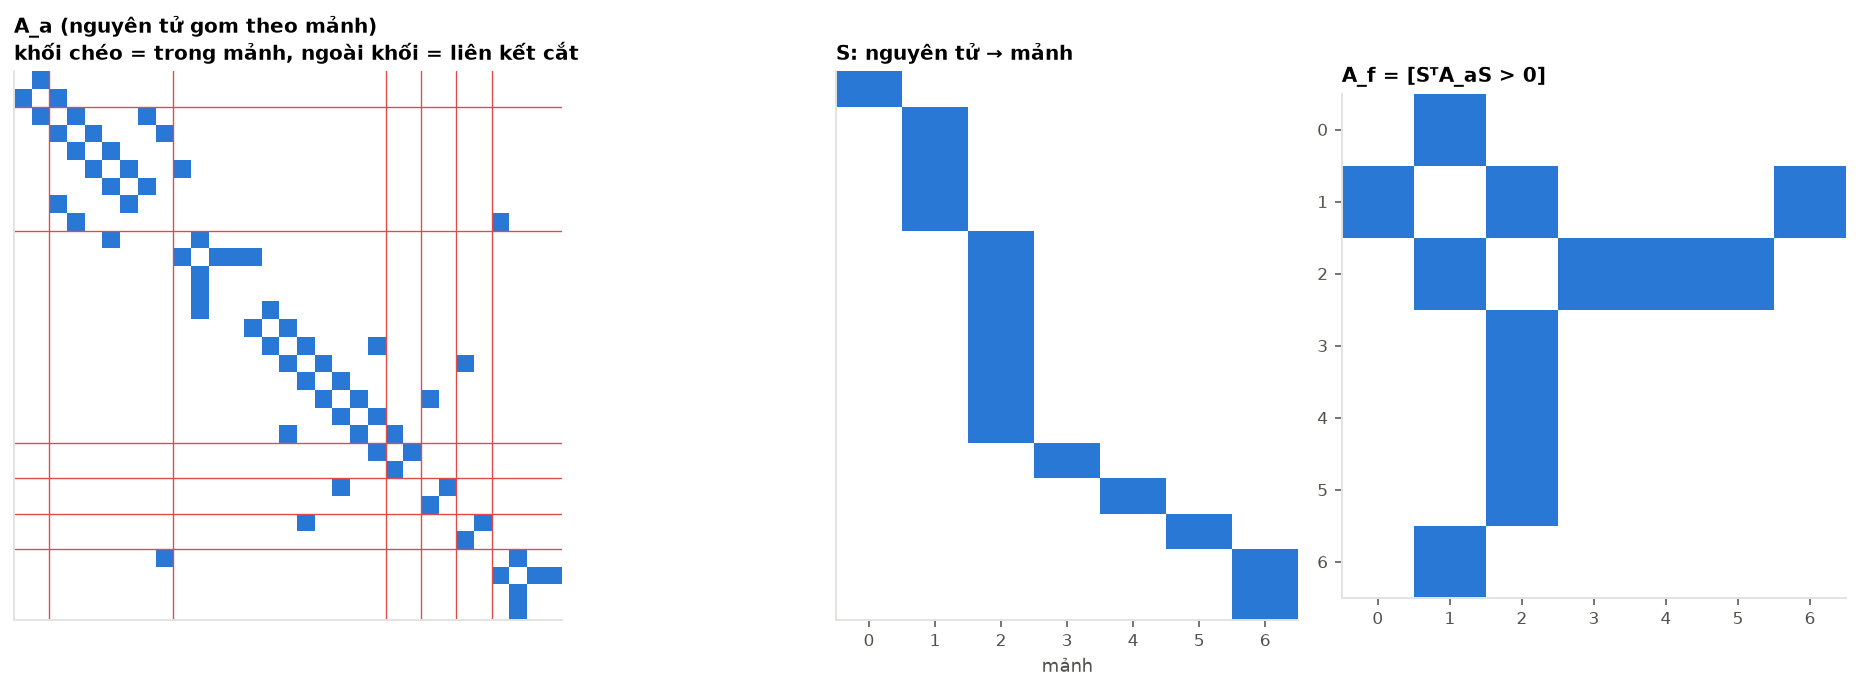

In [13]:
n_a, n_f = mol.GetNumAtoms(), fragmentation.n_fragments
S = np.zeros((n_a, n_f), dtype=int)
S[np.arange(n_a), fragmentation.atom_to_fragment] = 1
A_f = ((S.T @ A @ S) > 0).astype(int)
np.fill_diagonal(A_f, 0)

A_junction = np.zeros((n_f, n_f), dtype=int)
for _i, _j, fi, fj in fragmentation.junction_bonds:
    A_junction[fi, fj] = A_junction[fj, fi] = 1
assert (A_f == A_junction).all(), "S^T A S phải khớp với junction_bonds"
print("A_f từ S^T A S khớp với junction_bonds ✔")

order = np.argsort(fragmentation.atom_to_fragment, kind="stable")   # gom nguyên tử theo mảnh
fig, axes = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [1.2, 0.55, 0.6]})

ax = axes[0]
Ao = A[np.ix_(order, order)]
ax.imshow(Ao, cmap=ONEHOT, interpolation="nearest")
bounds = np.cumsum([len(f) for f in fragmentation.fragments])[:-1] - 0.5
for b in bounds:
    ax.axhline(b, color=CRIT, lw=0.7); ax.axvline(b, color=CRIT, lw=0.7)
ax.set_title("A_a (nguyên tử gom theo mảnh)\nkhối chéo = trong mảnh, ngoài khối = liên kết cắt",
             loc="left")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

ax = axes[1]
ax.imshow(S[order], aspect="auto", cmap=ONEHOT, interpolation="nearest")
ax.set_title("S: nguyên tử → mảnh", loc="left")
ax.set_xticks(range(n_f)); ax.set_xlabel("mảnh"); ax.set_yticks([]); ax.grid(False)

ax = axes[2]
ax.imshow(A_f, cmap=ONEHOT, interpolation="nearest")
ax.set_title("A_f = [SᵀA_aS > 0]", loc="left")
ax.set_xticks(range(n_f)); ax.set_yticks(range(n_f)); ax.grid(False)
plt.tight_layout()
plt.show()

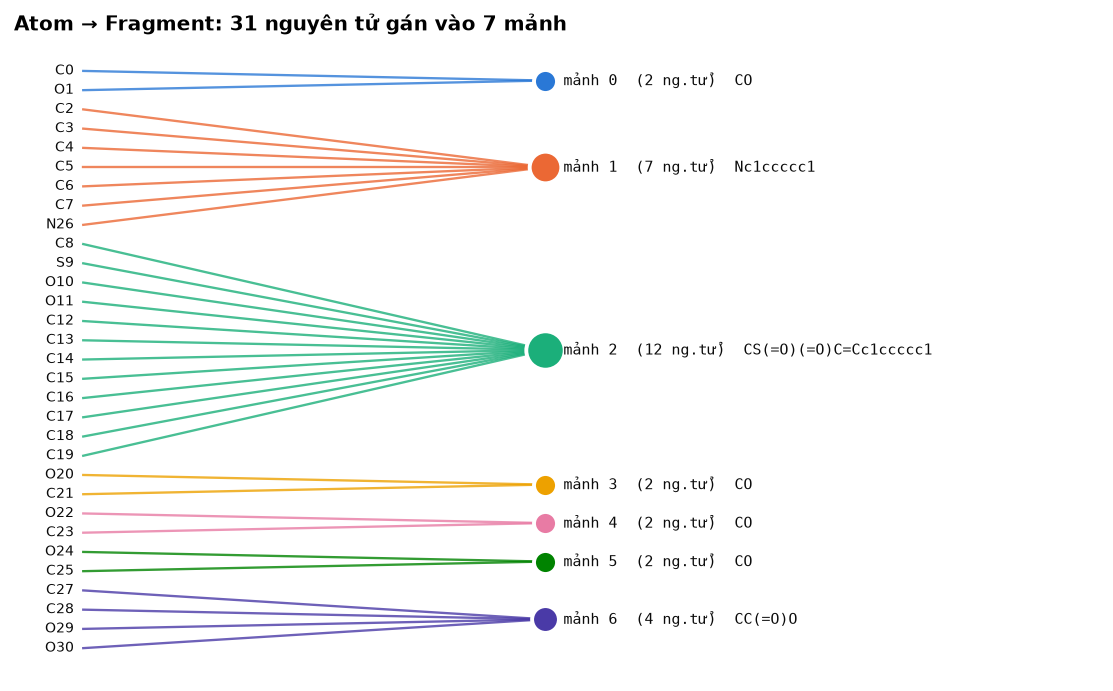

In [14]:
# Sơ đồ hai cột: mỗi nguyên tử (trái) nối tới mảnh chứa nó (phải).
a2f = fragmentation.atom_to_fragment
y_atom = {a: -r for r, a in enumerate(order)}
y_frag = {k: np.mean([y_atom[a] for a in atoms]) for k, atoms in enumerate(fragmentation.fragments)}

fig, ax = plt.subplots(figsize=(10, max(5, 0.19 * n_a)))
for a in range(n_a):
    k = a2f[a]
    ax.plot([0, 1], [y_atom[a], y_frag[k]], color=frag_colour(k), lw=1.2, alpha=0.8)
    ax.text(-0.02, y_atom[a], f"{mol.GetAtomWithIdx(a).GetSymbol()}{a}", ha="right",
            va="center", fontsize=7, color=INK)
for k in range(n_f):
    ax.scatter([1], [y_frag[k]], s=90 + 25 * len(fragmentation.fragments[k]),
               color=frag_colour(k), edgecolors="white", linewidths=2, zorder=3)
    ax.text(1.04, y_frag[k], f"mảnh {k}  ({len(fragmentation.fragments[k])} ng.tử)  {frag_smiles[k]}",
            va="center", fontsize=7.5, color=INK, family="DejaVu Sans Mono")
ax.set_xlim(-0.15, 2.2); ax.axis("off")
ax.set_title(f"Atom → Fragment: {n_a} nguyên tử gán vào {n_f} mảnh", loc="left")
plt.show()

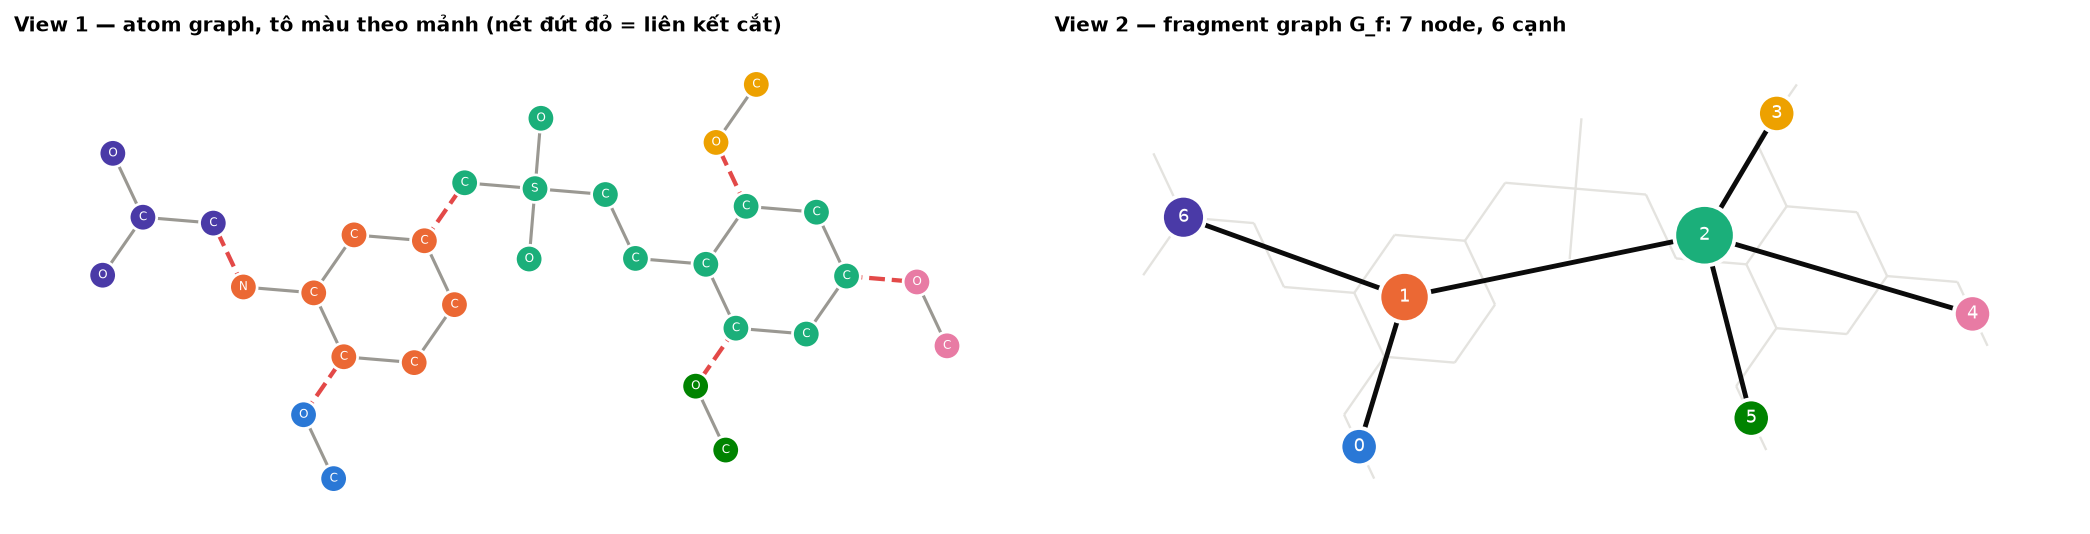

In [15]:
# Hai view cạnh nhau trên cùng bố cục 2D.
junction_pairs = {tuple(sorted((i, j))) for i, j, _fi, _fj in fragmentation.junction_bonds}
centroid = {k: coords[atoms].mean(0) for k, atoms in enumerate(fragmentation.fragments)}
G_frag = nx.Graph()
G_frag.add_nodes_from(range(n_f))
G_frag.add_edges_from((fi, fj) for _i, _j, fi, fj in fragmentation.junction_bonds)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
inner = [e for e in G_atom.edges if tuple(sorted(e)) not in junction_pairs]
nx.draw_networkx_edges(G_atom, pos, edgelist=inner, ax=ax, edge_color=NEUTRAL, width=1.6)
nx.draw_networkx_edges(G_atom, pos, edgelist=list(junction_pairs), ax=ax, edge_color=CRIT,
                       width=2.2, style="dashed")
nx.draw_networkx_nodes(G_atom, pos, ax=ax, node_size=200, edgecolors="white", linewidths=1.4,
                       node_color=[frag_colour(a2f[i]) for i in G_atom])
nx.draw_networkx_labels(G_atom, pos, ax=ax, font_size=6, font_color="white",
                        labels={i: mol.GetAtomWithIdx(i).GetSymbol() for i in G_atom})
ax.set_title("View 1 — atom graph, tô màu theo mảnh (nét đứt đỏ = liên kết cắt)", loc="left")
ax.set_aspect("equal"); ax.axis("off")

ax = axes[1]
nx.draw_networkx_edges(G_atom, pos, ax=ax, edge_color=GRID, width=1.2)
nx.draw_networkx_edges(G_frag, centroid, ax=ax, edge_color=INK, width=2.5)
nx.draw_networkx_nodes(G_frag, centroid, ax=ax, edgecolors="white", linewidths=2,
                       node_size=[250 + 60 * len(f) for f in fragmentation.fragments],
                       node_color=[frag_colour(k) for k in G_frag])
nx.draw_networkx_labels(G_frag, centroid, ax=ax, font_size=9, font_color="white",
                        labels={k: str(k) for k in G_frag})
ax.set_title(f"View 2 — fragment graph G_f: {n_f} node, {G_frag.number_of_edges()} cạnh", loc="left")
ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Vocabulary BRICS

DAF-DRP biểu diễn mỗi mảnh bằng **một hàng trong bảng embedding học được**, đánh chỉ số
theo SMILES chuẩn của mảnh. `build_vocabulary` đếm tần suất mọi mảnh BRICS trên toàn bộ
thuốc (`vocab_source: all`), giữ tối đa `|S| = 798` mảnh; chỉ số 0 dành cho OOV.

In [16]:
vocabulary = build_vocabulary(
    list(data.smiles.values()), frag_cfg,
    max_size=int(cfg["model"]["vocab_size"]),
    min_count=int(cfg["fragmenter"].get("min_vocab_count", 1)),
)
coverage = coverage_report(vocabulary, data.smiles, frag_cfg)
counts = vocabulary.counts
print(f"{len(counts)} mảnh khác nhau | giữ {len(vocabulary.index_of)} | bảng embedding {vocabulary.size} hàng")
print(f"{sum(n == 1 for n in counts.values())} mảnh chỉ xuất hiện đúng 1 lần")
print({k: round(v, 3) for k, v in coverage.items()})

# Mảnh của phân tử mẫu, ánh xạ sang index trong vocabulary
pd.DataFrame({"mảnh": range(n_f), "SMILES": frag_smiles,
              "vocab id": vocabulary.encode(frag_smiles),
              "tần suất": [counts[s] for s in frag_smiles]})

11:00:35 | BRICS vocabulary: 89 distinct fragments from 33 molecules (0 unparseable); kept 89 (cap 798, min_count 1); 69 occur exactly once


89 mảnh khác nhau | giữ 89 | bảng embedding 798 hàng
69 mảnh chỉ xuất hiện đúng 1 lần
{'drugs': 33, 'fragment_coverage': 1.0, 'atom_coverage': 1.0, 'fully_covered_drugs': 1.0}


,mảnh,SMILES,vocab id,tần suất
0,0,CO,1,24
1,1,Nc1ccccc1,8,4
2,2,CS(=O)(=O)C=Cc1ccccc1,55,1
3,3,CO,1,24
4,4,CO,1,24
5,5,CO,1,24
6,6,CC(=O)O,20,2


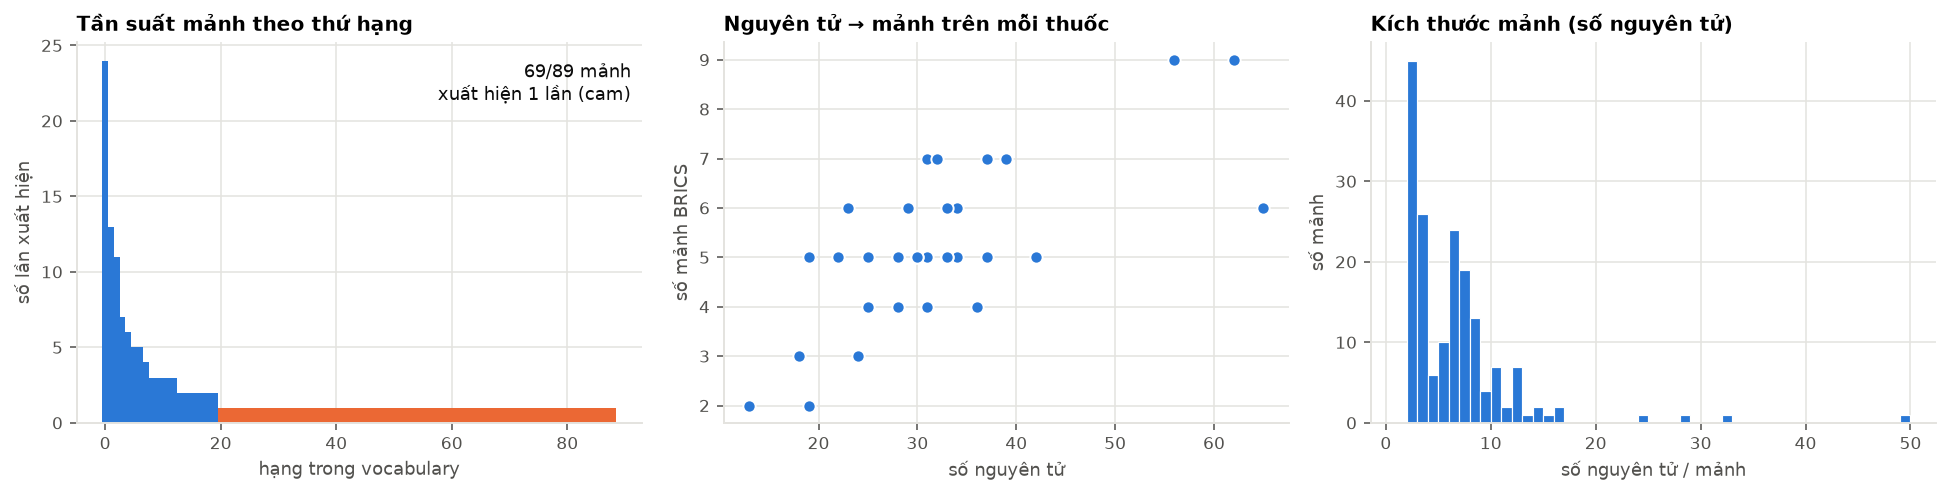

trung bình 32.0 nguyên tử → 5.2 mảnh / phân tử (nén ~6.1×)


In [17]:
per_drug_stats = []
frag_sizes = []
for d, smi in data.smiles.items():
    out = decompose(smi, frag_cfg)
    if out is None:
        continue
    m, fr = out
    per_drug_stats.append((d, m.GetNumAtoms(), fr.n_fragments))
    frag_sizes += [len(f) for f in fr.fragments]
per_drug_stats = pd.DataFrame(per_drug_stats, columns=["drug", "n_atoms", "n_fragments"])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
ax = axes[0]
freq = np.array(sorted(counts.values(), reverse=True))
ax.bar(range(len(freq)), freq, width=1.0, color=np.where(freq == 1, ORANGE, BLUE))
ax.set_title("Tần suất mảnh theo thứ hạng", loc="left")
ax.set_xlabel("hạng trong vocabulary"); ax.set_ylabel("số lần xuất hiện")
ax.text(0.98, 0.95, f"{(freq == 1).sum()}/{len(freq)} mảnh\nxuất hiện 1 lần (cam)",
        transform=ax.transAxes, ha="right", va="top", color=INK)

ax = axes[1]
ax.scatter(per_drug_stats["n_atoms"], per_drug_stats["n_fragments"], s=40, color=BLUE,
           edgecolors="white", linewidths=1)
ax.set_title("Nguyên tử → mảnh trên mỗi thuốc", loc="left")
ax.set_xlabel("số nguyên tử"); ax.set_ylabel("số mảnh BRICS")

ax = axes[2]
ax.hist(frag_sizes, bins=range(1, max(frag_sizes) + 2), color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_title("Kích thước mảnh (số nguyên tử)", loc="left")
ax.set_xlabel("số nguyên tử / mảnh"); ax.set_ylabel("số mảnh")
plt.tight_layout()
plt.show()
print(f"trung bình {per_drug_stats.n_atoms.mean():.1f} nguyên tử → {per_drug_stats.n_fragments.mean():.1f} mảnh "
      f"/ phân tử (nén ~{per_drug_stats.n_atoms.sum() / per_drug_stats.n_fragments.sum():.1f}×)")

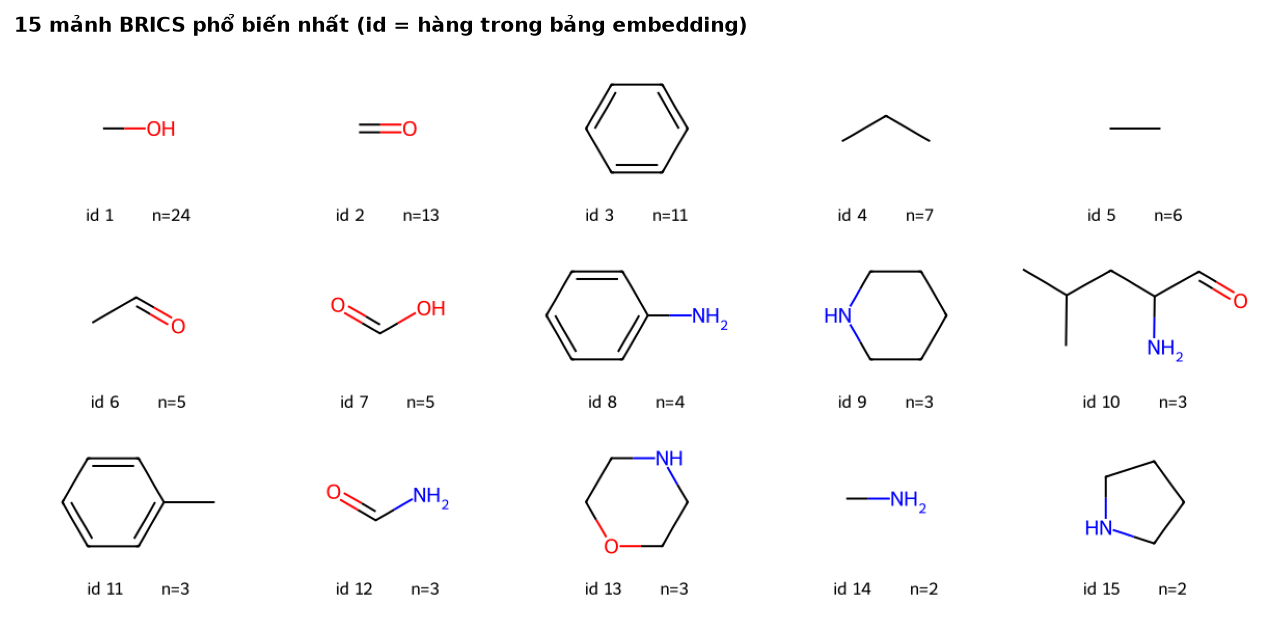

In [18]:
# Các mảnh phổ biến nhất trong vocabulary
top = counts.most_common(15)
mols = []
for s, _n in top:
    m = Chem.MolFromSmiles(s) or Chem.MolFromSmiles(s, sanitize=False)
    mols.append(m)
per_row, sw, sh = 5, 240, 180
grid = rdMolDraw2D.MolDraw2DCairo(per_row * sw, -(-len(mols) // per_row) * sh, sw, sh)
grid.DrawMolecules(mols, legends=[f"id {vocabulary.index_of[s]} · n={n}" for s, n in top])
grid.FinishDrawing()
plt.figure(figsize=(12, 5.2))
show_png(grid.GetDrawingText(), title="15 mảnh BRICS phổ biến nhất (id = hàng trong bảng embedding)")
plt.show()

### Coverage khi vocabulary chỉ được mine trên thuốc train

Mặc định `vocab_source: all` mine trên **mọi** thuốc — hào phóng, vì thuốc test cũng góp
mảnh vào vocabulary. Nếu mine riêng trên thuốc train của từng fold (không leak), bao nhiêu
mảnh của thuốc test sẽ rơi vào OOV?

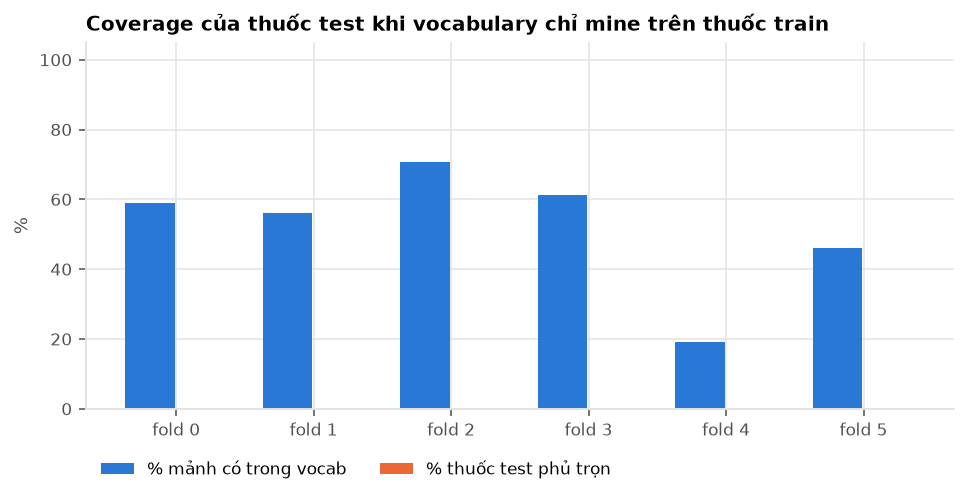

,fold,drugs,fragment_coverage,atom_coverage,fully_covered_drugs
0,0,6,0.590,0.365,0.0
1,1,6,0.562,0.329,0.0
2,2,5,0.708,0.296,0.0
3,3,6,0.613,0.379,0.0
4,4,5,0.190,0.131,0.0
5,5,5,0.462,0.288,0.0


In [19]:
logging.getLogger("fragment_vocab").setLevel(logging.WARNING)
rows = []
for f in folds:
    train_drugs = sorted(set(data.drug_ids[f.train]))
    test_drugs = sorted(set(data.drug_ids[f.test]))
    v_train = build_vocabulary([data.smiles[d] for d in train_drugs], frag_cfg,
                               max_size=int(cfg["model"]["vocab_size"]))
    cov = coverage_report(v_train, {d: data.smiles[d] for d in test_drugs}, frag_cfg)
    rows.append({"fold": f.index, **cov})
logging.getLogger("fragment_vocab").setLevel(logging.INFO)
cov_train = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(cov_train)); w = 0.38
ax.bar(x - w / 2, 100 * cov_train["fragment_coverage"], w - 0.02, color=BLUE, label="% mảnh có trong vocab")
ax.bar(x + w / 2, 100 * cov_train["fully_covered_drugs"], w - 0.02, color=ORANGE,
       label="% thuốc test phủ trọn")
ax.set_xticks(x, [f"fold {i}" for i in x]); ax.set_ylim(0, 105); ax.set_ylabel("%")
ax.set_title("Coverage của thuốc test khi vocabulary chỉ mine trên thuốc train", loc="left")
ax.legend(ncol=2, loc="upper left", bbox_to_anchor=(0, -0.1))
plt.show()
cov_train.round(3)

## 8. `DualGraph` — thứ mô hình thực sự nhận vào

`data.featurize` gói hai view lại: `atom_x` + `atom_edge_index` cho nhánh atom, và
`frag_vocab_ids` + `frag_edge_index` cho nhánh fragment. Nhánh fragment **không có
feature** — node chỉ là một số nguyên.

In [20]:
drug_graphs = build_drug_graphs(data.smiles, vocabulary, frag_cfg)
g = drug_graphs[EXAMPLE_DRUG]
pd.DataFrame([
    ("atom_x", g.atom_x.shape, "float32 — feature nguyên tử"),
    ("atom_edge_index", g.atom_edge_index.shape, "2 × (2·số liên kết)"),
    ("frag_vocab_ids", g.frag_vocab_ids.shape, str(g.frag_vocab_ids.tolist())),
    ("frag_edge_index", g.frag_edge_index.shape, "2 × (2·số junction)"),
    ("n_oov", g.n_oov, "số mảnh ngoài vocabulary"),
], columns=["trường", "shape / giá trị", "ghi chú"])

11:00:36 | Featurised 33/33 drugs | 5.2 fragments/molecule | 0/173 fragments out-of-vocabulary (0.0%)


,trường,shape / giá trị,ghi chú
0,atom_x,"(31, 49)",float32 — feature nguyên tử
1,atom_edge_index,"(2, 64)",2 × (2·số liên kết)
2,frag_vocab_ids,"(7,)","[1, 8, 55, 1, 1, 1, 20]"
3,frag_edge_index,"(2, 12)",2 × (2·số junction)
4,n_oov,0,số mảnh ngoài vocabulary


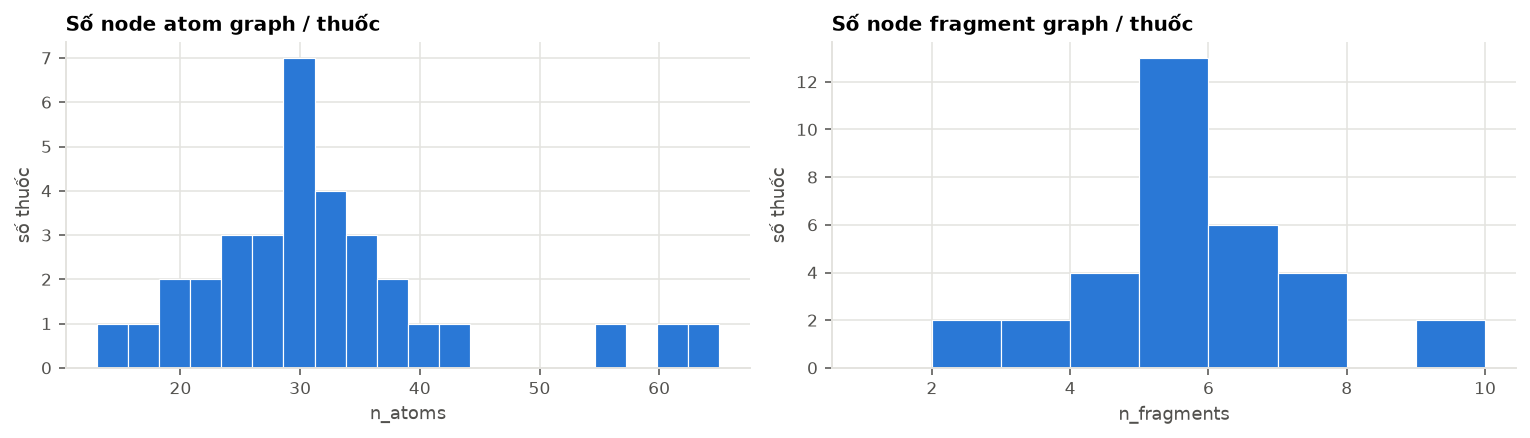

In [21]:
na = np.array([gr.n_atoms for gr in drug_graphs.values()])
nf = np.array([gr.n_fragments for gr in drug_graphs.values()])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(na, bins=20, color=BLUE, edgecolor="white", linewidth=0.6)
axes[0].set_title("Số node atom graph / thuốc", loc="left"); axes[0].set_xlabel("n_atoms")
axes[1].hist(nf, bins=range(1, nf.max() + 2), color=BLUE, edgecolor="white", linewidth=0.6)
axes[1].set_title("Số node fragment graph / thuốc", loc="left"); axes[1].set_xlabel("n_fragments")
for ax in axes:
    ax.set_ylabel("số thuốc")
plt.tight_layout()
plt.show()

## 9. Dataset, scaler và batching

Giống hệt `train.run_fold`: scaler gene expression và scaler response được fit **chỉ trên
fold train**. `collate` ghép nhiều đồ thị thành một đồ thị rời rạc lớn (dịch chỉ số node)
và vector `batch` cho biết node thuộc mẫu nào — `SumPool` dùng nó để cộng theo từng mẫu.

train:  1253 cặp |  24 thuốc |  87 cell line
val  :   115 cặp |   3 thuốc |  75 cell line
test :   290 cặp |   6 thuốc |  86 cell line


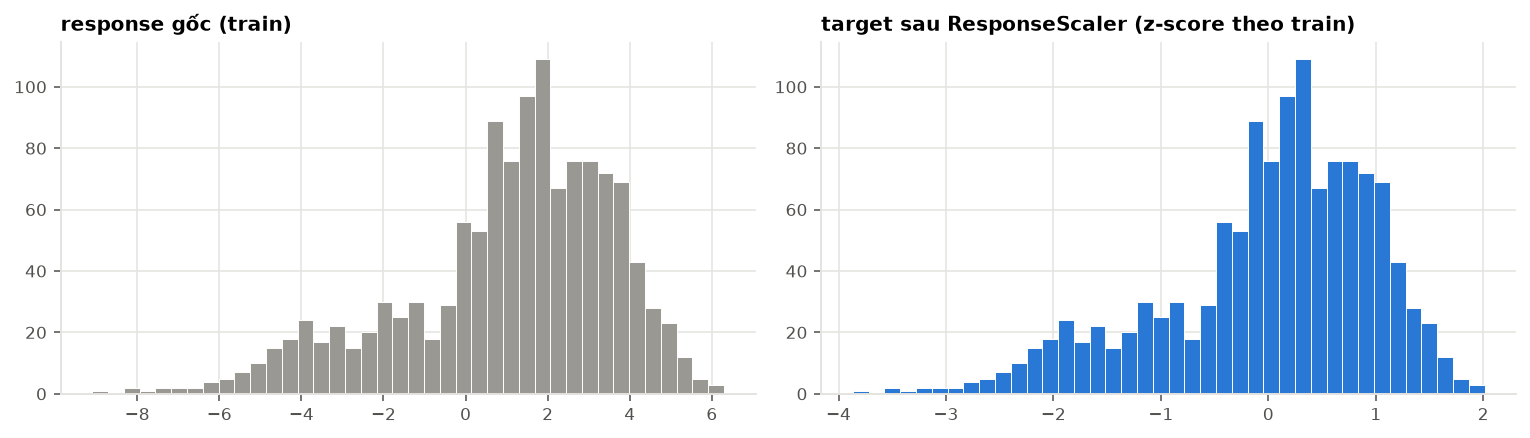

In [22]:
fold = folds[FOLD]
tcfg, mcfg = cfg["train"], cfg["model"]
device = resolve_device(tcfg["device"])
set_seed(int(tcfg["seed"]) + fold.index)

train_cells = sorted({str(c) for c in data.cell_line_ids[fold.train]})
cell_scaler = StandardScaler().fit(np.stack([data.cell_line_features[c] for c in train_cells]))
response_scaler = ResponseScaler(enabled=cfg["data"]["response_transform"] == "standard").fit(
    data.response[fold.train])

sets = {name_: DualDataset(data, rows_, drug_graphs, cell_scaler, response_scaler)
        for name_, rows_ in (("train", fold.train), ("val", fold.validation), ("test", fold.test))}
loaders = {
    "train": make_loader(sets["train"], int(tcfg["batch_size"]), True),
    "val": make_loader(sets["val"], int(tcfg["batch_size"]) * 2, False),
    "test": make_loader(sets["test"], int(tcfg["batch_size"]) * 2, False),
}
for k, s in sets.items():
    print(f"{k:5s}: {len(s):5d} cặp | {len(set(s.drug_ids)):3d} thuốc | {len(set(s.cell_ids)):3d} cell line")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(sets["train"].raw_response, bins=40, color=NEUTRAL, edgecolor="white", linewidth=0.5)
axes[0].set_title("response gốc (train)", loc="left")
axes[1].hist(sets["train"].target, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set_title("target sau ResponseScaler (z-score theo train)", loc="left")
plt.tight_layout()
plt.show()

atom_x           (117, 49)
atom_edge_index  (2, 250)
atom_batch       (117,)
frag_vocab_ids   (18,)
frag_edge_index  (2, 28)
frag_batch       (18,)
cell             (4, 13)
target           (4,)


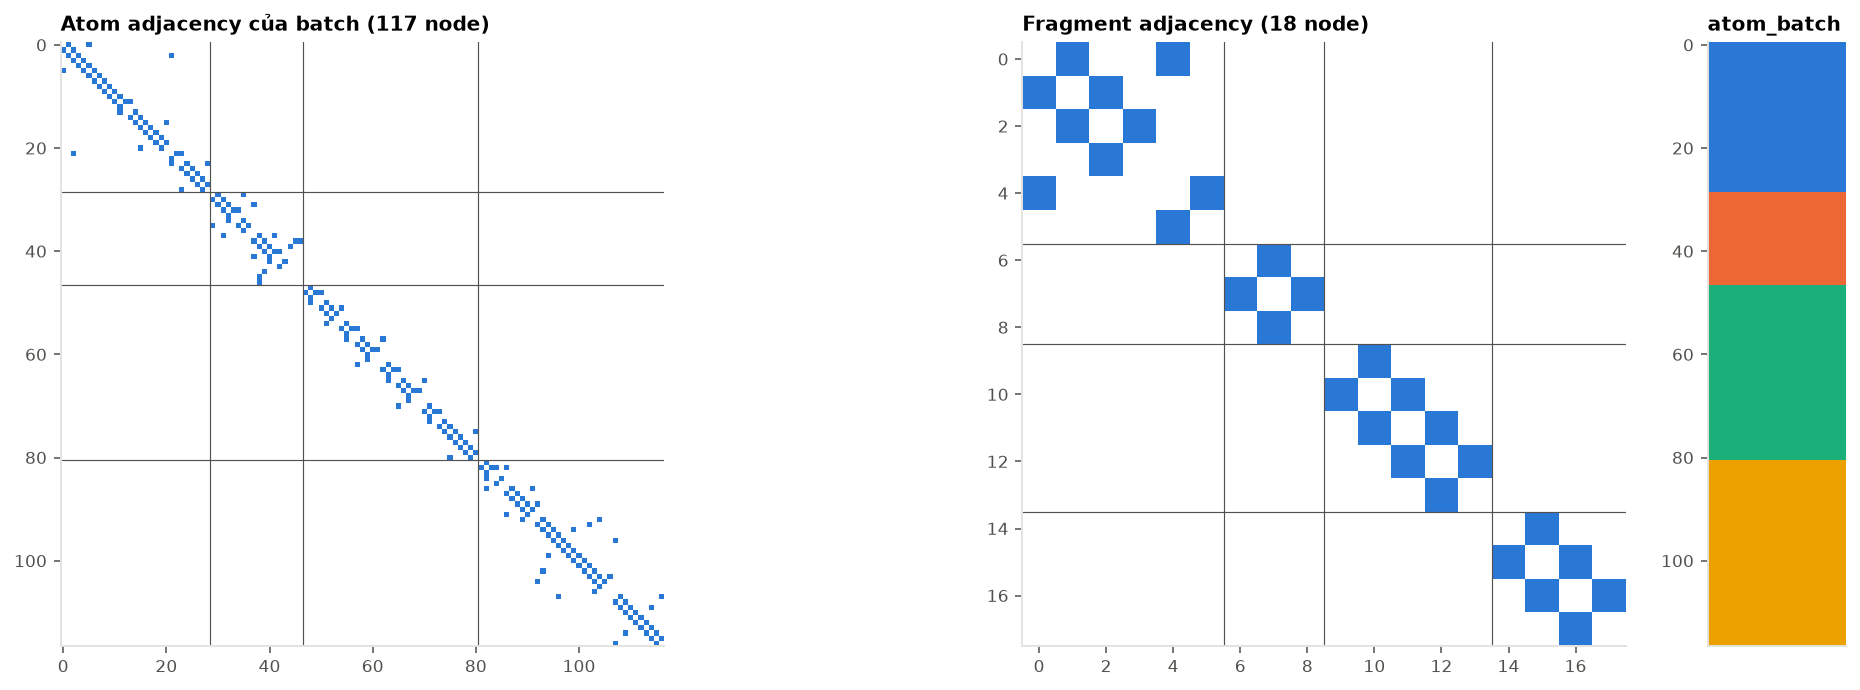

frag_vocab_ids: [9, 21, 6, 22, 2, 3, 28, 29, 1, 10, 10, 10, 7, 11, 33, 3, 34, 35]
frag_batch    : [0, 0, 0, 0, 0, 0, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 3]


In [23]:
# Một mini-batch nhỏ gồm 4 thuốc khác nhau để nhìn cấu trúc block-diagonal
picked, seen = [], set()
for i in range(len(sets["train"])):
    item = sets["train"][i]
    if item["drug_id"] not in seen:
        picked.append(item); seen.add(item["drug_id"])
    if len(picked) == 4:
        break
mini = collate(picked)
for f_ in ("atom_x", "atom_edge_index", "atom_batch", "frag_vocab_ids", "frag_edge_index",
           "frag_batch", "cell", "target"):
    print(f"{f_:16s} {tuple(getattr(mini, f_).shape)}")


def dense(edge_index, n):
    M = np.zeros((n, n))
    ei = edge_index.numpy()
    M[ei[0], ei[1]] = 1
    return M


fig, axes = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 0.55, 0.12]})
axes[0].imshow(dense(mini.atom_edge_index, mini.atom_x.shape[0]), cmap=ONEHOT, interpolation="nearest")
axes[0].set_title(f"Atom adjacency của batch ({mini.atom_x.shape[0]} node)", loc="left")
axes[1].imshow(dense(mini.frag_edge_index, mini.frag_vocab_ids.shape[0]), cmap=ONEHOT,
               interpolation="nearest")
axes[1].set_title(f"Fragment adjacency ({mini.frag_vocab_ids.shape[0]} node)", loc="left")
axes[2].imshow(mini.atom_batch.numpy()[:, None], aspect="auto",
               cmap=ListedColormap(FRAGMENT_COLOURS[:4]), interpolation="nearest")
axes[2].set_title("atom_batch", loc="left"); axes[2].set_xticks([])
atom_bounds = np.flatnonzero(np.diff(mini.atom_batch.numpy())) + 0.5
frag_bounds = np.flatnonzero(np.diff(mini.frag_batch.numpy())) + 0.5
for ax, bounds in ((axes[0], atom_bounds), (axes[1], frag_bounds), (axes[2], [])):
    for b in bounds:
        ax.axhline(b, color=MUTED, lw=0.6); ax.axvline(b, color=MUTED, lw=0.6)
    ax.grid(False)
plt.tight_layout()
plt.show()
print("frag_vocab_ids:", mini.frag_vocab_ids.tolist())
print("frag_batch    :", mini.frag_batch.tolist())

## 10. Mô hình — forward từng tầng

```
AtomGraph  G_a ─► GIN_θa (5 lớp) ─► SumPool ─► z_a ∈ R^128
FragGraph  G_f ─► Embedding[vocab id] ─► GIN_θf (5 lớp) ─► SumPool ─► z_f ∈ R^128
expression x_c ─► FC_ge ──────────────────────────────────► h_c ∈ R^128

z_drug = O_drug(z_a, z_f)        h_final = O_global(z_drug, h_c)        ŷ = MLP(h_final)
```

Cấu hình mặc định là **WA** (DrugFusion = Weighted-add, GlobalFusion = Cross-attention) —
cấu hình tốt nhất trong bài báo. Ta gắn forward hook để bắt tensor trung gian.

DAF-DRP(BRICS)_WA  dim=128  params=1,022,604  [Eq.6 as printed: softmax over 1 key = 1]


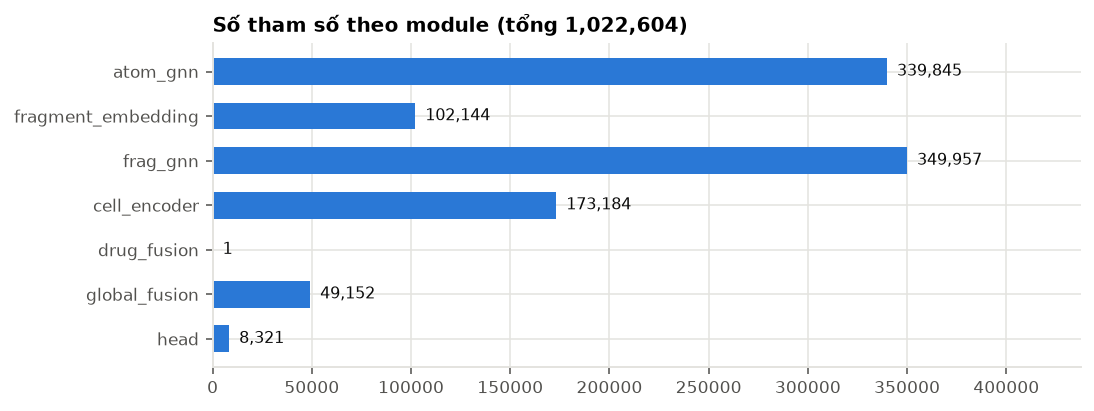

In [24]:
def build_model(fix_attention=None):
    fix = mcfg.get("fix_degenerate_attention", False) if fix_attention is None else fix_attention
    return DAFDRPBrics(
        n_genes=data.n_genes, atom_feature_dim=ATOM_DIM, vocab_size=int(mcfg["vocab_size"]),
        dim=int(mcfg["dim"]), atom_layers=int(mcfg["atom_layers"]),
        frag_layers=int(mcfg["frag_layers"]), dropout=float(mcfg["dropout"]),
        drug_fusion=mcfg["drug_fusion"], global_fusion=mcfg["global_fusion"],
        head_dims=list(mcfg["head_dims"]),
        fix_degenerate_attention=bool(fix),
    ).to(device)


set_seed(int(tcfg["seed"]) + fold.index)
model = build_model()
print(model.describe())

parts = {"atom_gnn": model.atom_gnn, "fragment_embedding": model.fragment_embedding,
         "frag_gnn": model.frag_gnn, "cell_encoder": model.cell_encoder,
         "drug_fusion": model.drug_fusion, "global_fusion": model.global_fusion, "head": model.head}
n_params = pd.Series({k: sum(p.numel() for p in m.parameters()) for k, m in parts.items()})
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(n_params.index[::-1], n_params.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(n_params.values[::-1]):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=8, color=INK)
ax.set_title(f"Số tham số theo module (tổng {n_params.sum():,})", loc="left")
ax.set_xlim(0, n_params.max() * 1.25)
plt.show()

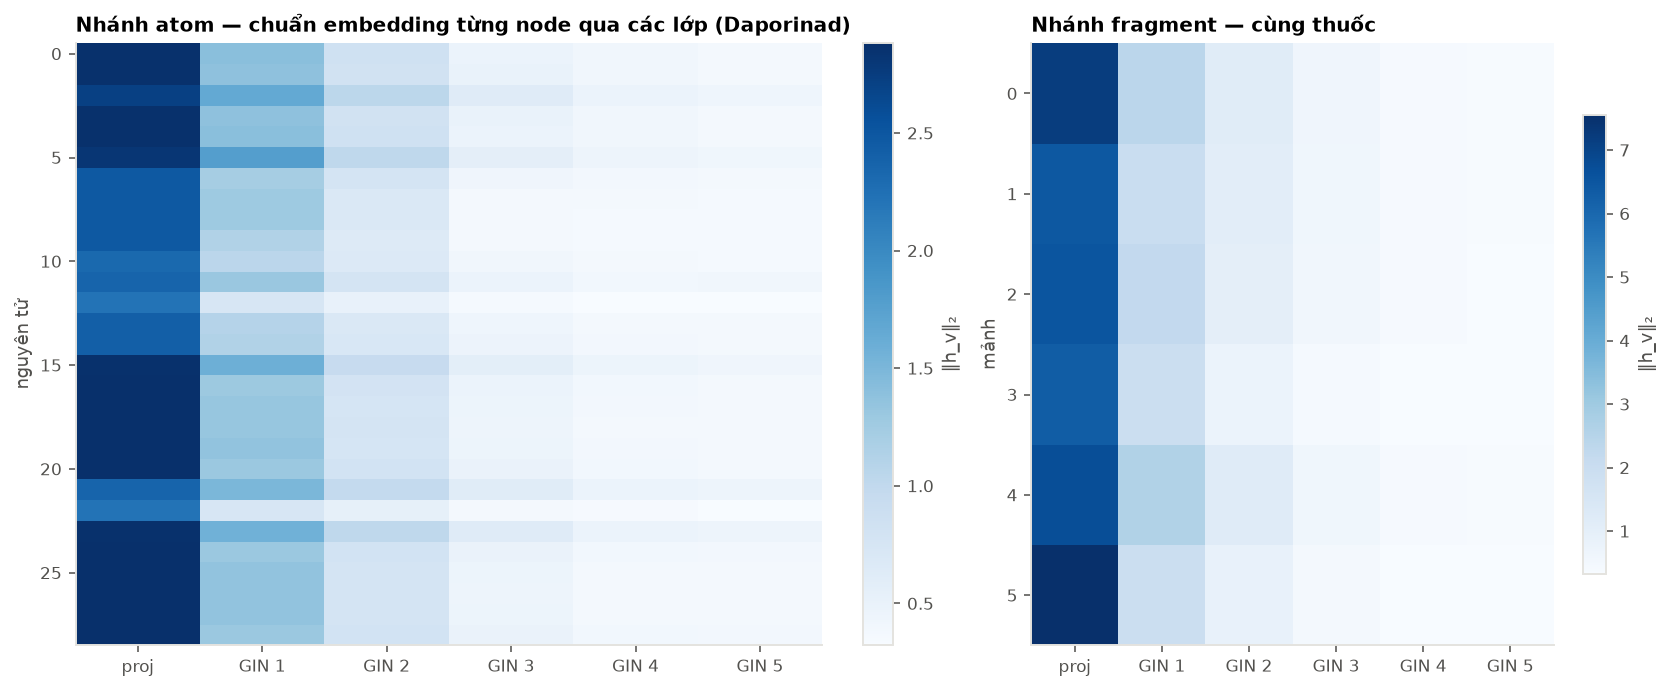

In [25]:
captured = {}


def hook(name_):
    def fn(_module, _inp, out):
        captured[name_] = out.detach().float().cpu()
    return fn


handles = [model.atom_gnn.input_projection.register_forward_hook(hook("atom_L0")),
           model.frag_gnn.input_projection.register_forward_hook(hook("frag_L0")),
           model.fragment_embedding.register_forward_hook(hook("frag_emb")),
           model.cell_encoder.register_forward_hook(hook("h_c")),
           model.drug_fusion.register_forward_hook(hook("z_drug")),
           model.global_fusion.register_forward_hook(hook("h_final"))]
for i, layer in enumerate(model.atom_gnn.layers):
    handles.append(layer.register_forward_hook(hook(f"atom_L{i + 1}")))
for i, layer in enumerate(model.frag_gnn.layers):
    handles.append(layer.register_forward_hook(hook(f"frag_L{i + 1}")))

model.eval()
with torch.no_grad():
    batch_dev = mini.to(device)
    z_a = model.atom_gnn(batch_dev.atom_x, batch_dev.atom_edge_index, batch_dev.atom_batch, mini.n_graphs)
    z_f = model.frag_gnn(model.fragment_embedding(batch_dev.frag_vocab_ids), batch_dev.frag_edge_index,
                         batch_dev.frag_batch, mini.n_graphs)
    pred = model(batch_dev)["prediction"]
for h_ in handles:
    h_.remove()

L = int(mcfg["atom_layers"])
atom_mask = (mini.atom_batch == 0).numpy()
frag_mask = (mini.frag_batch == 0).numpy()
atom_norms = np.stack([captured[f"atom_L{i}"][atom_mask].norm(dim=1).numpy() for i in range(L + 1)], 1)
frag_norms = np.stack([captured[f"frag_L{i}"][frag_mask].norm(dim=1).numpy() for i in range(L + 1)], 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 0.7]})
for ax, M, lab in ((axes[0], atom_norms, "nguyên tử"), (axes[1], frag_norms, "mảnh")):
    im = ax.imshow(M, aspect="auto", cmap=SEQ, interpolation="nearest")
    ax.set_xticks(range(L + 1), ["proj"] + [f"GIN {i}" for i in range(1, L + 1)])
    ax.set_ylabel(lab); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.04, label="‖h_v‖₂")
drug0 = names.get(mini.drug_ids[0], mini.drug_ids[0])
axes[0].set_title(f"Nhánh atom — chuẩn embedding từng node qua các lớp ({drug0})", loc="left")
axes[1].set_title("Nhánh fragment — cùng thuốc", loc="left")
plt.tight_layout()
plt.show()

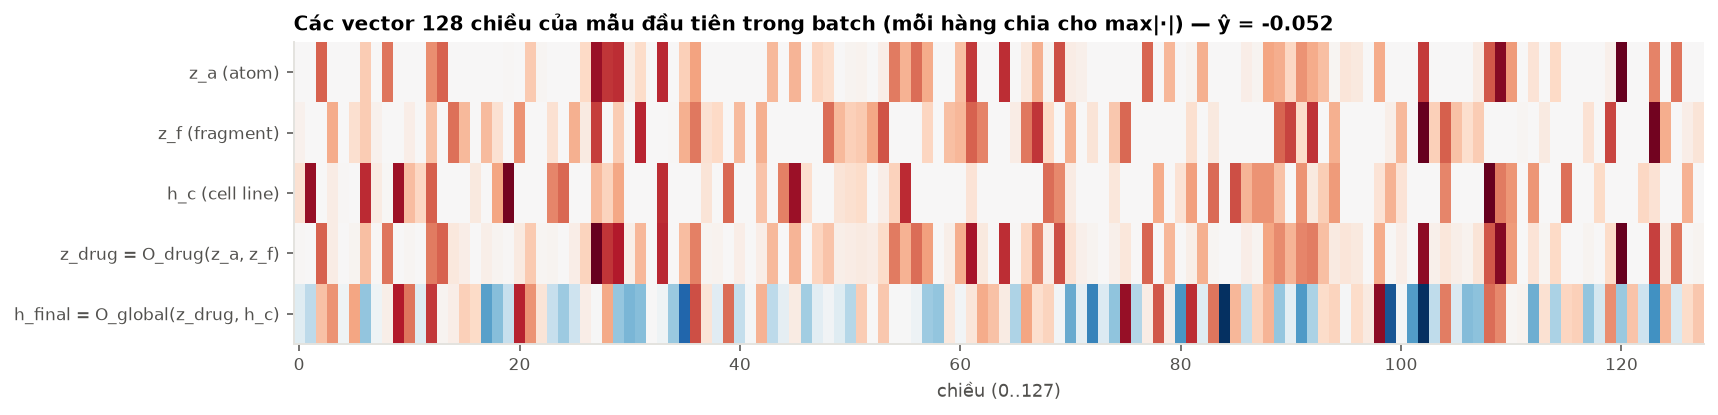

In [26]:
vectors = {"z_a (atom)": z_a[0].float().cpu(), "z_f (fragment)": z_f[0].float().cpu(),
           "h_c (cell line)": captured["h_c"][0], "z_drug = O_drug(z_a, z_f)": captured["z_drug"][0],
           "h_final = O_global(z_drug, h_c)": captured["h_final"][0]}
V = np.stack([v.numpy() for v in vectors.values()])
V = V / (np.abs(V).max(1, keepdims=True) + 1e-8)       # chuẩn hoá từng hàng để cùng thang màu

fig, ax = plt.subplots(figsize=(13, 2.8))
ax.imshow(V, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(vectors)), list(vectors)); ax.set_xlabel("chiều (0..127)"); ax.grid(False)
ax.set_title(f"Các vector 128 chiều của mẫu đầu tiên trong batch (mỗi hàng chia cho max|·|) — ŷ = {pred[0].item():+.3f}",
             loc="left")
plt.show()

### Hai phép fusion ở trạng thái khởi tạo

* **Weighted-add**: $O_\alpha(a,b)=\alpha a+(1-\alpha)b$, với $\alpha=\sigma(\text{logit})$, khởi tạo $0.5$.
* **Cross-attention (Eq. 6 đúng như bài báo)**: `a`, `b` là vector đã pool, nên
  $aW_Q(bW_K)^\top$ là **một số vô hướng**, softmax trên một phần tử luôn bằng 1, và phép
  toán suy biến thành $bW_V$ — bỏ hẳn query.

Hệ quả quan trọng hơn: vì $\mathrm{softmax}$ của một phần tử là hằng số 1, **đạo hàm theo
query bằng 0**. Trong cấu hình WA, query của GlobalFusion là $z_{drug}$ — nên *không có
gradient nào chảy về nhánh thuốc* (atom GNN, bảng embedding mảnh, fragment GNN). Ô dưới
kiểm tra cả hai điều bằng số.

In [27]:
if isinstance(model.drug_fusion, WeightedAdditionFusion):
    print(f"DrugFusion  W: alpha = {model.drug_fusion.alpha.item():.3f}")

ga = model.global_fusion if isinstance(model.global_fusion, CrossAttentionFusion) else (
     model.drug_fusion if isinstance(model.drug_fusion, CrossAttentionFusion) else None)
if ga is not None:
    a_in = captured["z_drug"].to(device) if ga is model.global_fusion else z_a.float()
    b_in = captured["h_c"].to(device) if ga is model.global_fusion else z_f.float()
    with torch.no_grad():
        q, k_, v = ga.query(a_in), ga.key(b_in), ga.value(b_in)
        score = (q * k_).sum(-1, keepdim=True) * ga.scale
        weight = torch.softmax(score, dim=-1)
        out = ga(a_in, b_in)
    print("score shape       :", tuple(score.shape), "  (một số cho mỗi mẫu)")
    print("score             :", score.ravel().cpu().numpy().round(3))
    print("softmax(score)    :", weight.ravel().cpu().numpy())
    print("O_attn == b·W_V ? :", torch.allclose(out, v, atol=1e-6),
          "| fix_degenerate =", ga.fix_degenerate)

    a_req = a_in.detach().clone().requires_grad_(True)
    ga(a_req, b_in).sum().backward()
    print("‖∂O_attn/∂a‖      :", a_req.grad.norm().item(), " (a = query = z_drug trong WA)")
    model.zero_grad(set_to_none=True)

DrugFusion  W: alpha = 0.500
score shape       : (4, 1)   (một số cho mỗi mẫu)
score             : [ 0.008 -0.002  0.001 -0.007]
softmax(score)    : [1. 1. 1. 1.]
O_attn == b·W_V ? : True | fix_degenerate = False
‖∂O_attn/∂a‖      : 0.0  (a = query = z_drug trong WA)


## 11. Huấn luyện một fold — log từng step

Vì phát hiện ở bước 10, ta huấn luyện **hai biến thể** trên cùng fold, cùng seed:

* **Eq. 6 như bài báo** (`fix_degenerate_attention: false`, mặc định của `config.yaml`);
* **Eq. 6 đã sửa** (`--fix-attention`): cổng bilinear giữ cả hai đầu vào.

Vòng lặp **giống hệt `train.run_fold`** (Adam, MSE, AMP, early stopping theo val MSE,
khôi phục trọng số tốt nhất), chỉ thêm việc ghi lại loss từng step, metric val từng epoch,
chuẩn gradient của từng nhánh và giá trị $\alpha$.

In [28]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, targets, drugs, cells = [], [], [], []
    for batch in loader:
        batch = batch.to(device)
        with torch.amp.autocast("cuda", enabled=use_amp):
            out = model(batch)["prediction"]
        preds.append(out.float().cpu().numpy())
        targets.append(batch.raw_response.cpu().numpy())
        drugs += batch.drug_ids
        cells += batch.cell_line_ids
    return {"predictions": response_scaler.inverse_transform(np.concatenate(preds)),
            "targets": np.concatenate(targets), "drug_ids": drugs, "cell_line_ids": cells}


def group_grad_norm(modules):
    sq = [p.grad.float().norm() ** 2 for m in modules for p in m.parameters() if p.grad is not None]
    return float(torch.sqrt(torch.stack(sq).sum())) if sq else 0.0


use_amp = bool(tcfg.get("amp", True)) and device.type == "cuda"
BRANCHES = ["atom_gnn", "fragment_embedding", "frag_gnn", "cell_encoder", "fusion + head"]


def train_fold(fix_attention: bool) -> dict:
    set_seed(int(tcfg["seed"]) + fold.index)
    model = build_model(fix_attention)
    emb_init = model.fragment_embedding.weight.detach().float().cpu().clone()
    groups = {"atom_gnn": [model.atom_gnn], "fragment_embedding": [model.fragment_embedding],
              "frag_gnn": [model.frag_gnn], "cell_encoder": [model.cell_encoder],
              "fusion + head": [model.drug_fusion, model.global_fusion, model.head]}
    optimizer = torch.optim.Adam(model.parameters(), lr=float(tcfg["lr"]),
                                 weight_decay=float(tcfg.get("weight_decay", 0.0)))
    criterion = nn.MSELoss()
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    step_log, epoch_log = [], []
    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    best_val, best_epoch, stale, step = float("inf"), 0, 0, 0
    started = time.time()
    for epoch in range(int(tcfg["max_epochs"])):
        model.train()
        grads = {k: [] for k in groups}
        for batch in loaders["train"]:
            batch = batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                loss = criterion(model(batch)["prediction"], batch.target)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)            # để đo gradient ở thang thật
            for k, mods in groups.items():
                grads[k].append(group_grad_norm(mods))
            if float(tcfg.get("grad_clip", 0.0)) > 0:
                nn.utils.clip_grad_norm_(model.parameters(), float(tcfg["grad_clip"]))
            scaler.step(optimizer)
            scaler.update()
            step_log.append({"step": step, "epoch": epoch, "loss": loss.item()})
            step += 1

        out = predict(model, loaders["val"])
        vm = compute_metrics(out["targets"], out["predictions"], out["drug_ids"], out["cell_line_ids"])
        val_mse = vm.get("mse", float("inf"))
        improved = val_mse < best_val - 1e-6
        if improved:
            best_val, best_epoch, stale = val_mse, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        epoch_log.append({
            "epoch": epoch, "val_mse": val_mse, "val_pearson": vm.get("pearson"),
            "val_pc_drug": vm.get("partial_correlation_drug"),
            "alpha": model.drug_fusion.alpha.item() if isinstance(model.drug_fusion, WeightedAdditionFusion) else np.nan,
            **{f"grad_{k}": np.mean([x for x in v if np.isfinite(x)] or [np.nan]) for k, v in grads.items()},
        })
        if epoch % 10 == 0:
            print(f"  epoch {epoch:3d} | val mse {val_mse:.4f} | "
                  f"{format_metrics(vm, ('pearson', 'partial_correlation_drug'))}")
        if stale >= int(tcfg["patience"]):
            break

    model.load_state_dict(best_state)
    print(f"  dừng ở epoch {epoch}, best epoch {best_epoch}, {time.time() - started:.1f}s")
    return {"model": model, "emb_init": emb_init, "best_epoch": best_epoch,
            "steps": pd.DataFrame(step_log), "epochs": pd.DataFrame(epoch_log)}


VARIANTS = {"Eq.6 như bài báo": False, "Eq.6 đã sửa": True}
VCOLOUR = {"Eq.6 như bài báo": ORANGE, "Eq.6 đã sửa": BLUE}
runs = {}
for label, fix in VARIANTS.items():
    print(f"=== {label} (fix_degenerate_attention={fix}) ===")
    runs[label] = train_fold(fix)

=== Eq.6 như bài báo (fix_degenerate_attention=False) ===


  epoch   0 | val mse 5.5430 | pearson=-0.0157  partial_correlation_drug=0.0094


  epoch  10 | val mse 5.0340 | pearson=0.2386  partial_correlation_drug=0.2750


  epoch  20 | val mse 4.9334 | pearson=0.2702  partial_correlation_drug=0.2874


  epoch  30 | val mse 4.8315 | pearson=0.2963  partial_correlation_drug=0.2924


...

  epoch   0 | val mse 5.4648 | pearson=0.3537  partial_correlation_drug=0.2113


  epoch  10 | val mse 2.5994 | pearson=0.6873  partial_correlation_drug=0.2215


  epoch  20 | val mse 2.5069 | pearson=0.6922  partial_correlation_drug=0.2458


  epoch  30 | val mse 2.5962 | pearson=0.6736  partial_correlation_drug=0.2871


  dừng ở epoch 37, best epoch 17, 6.4s


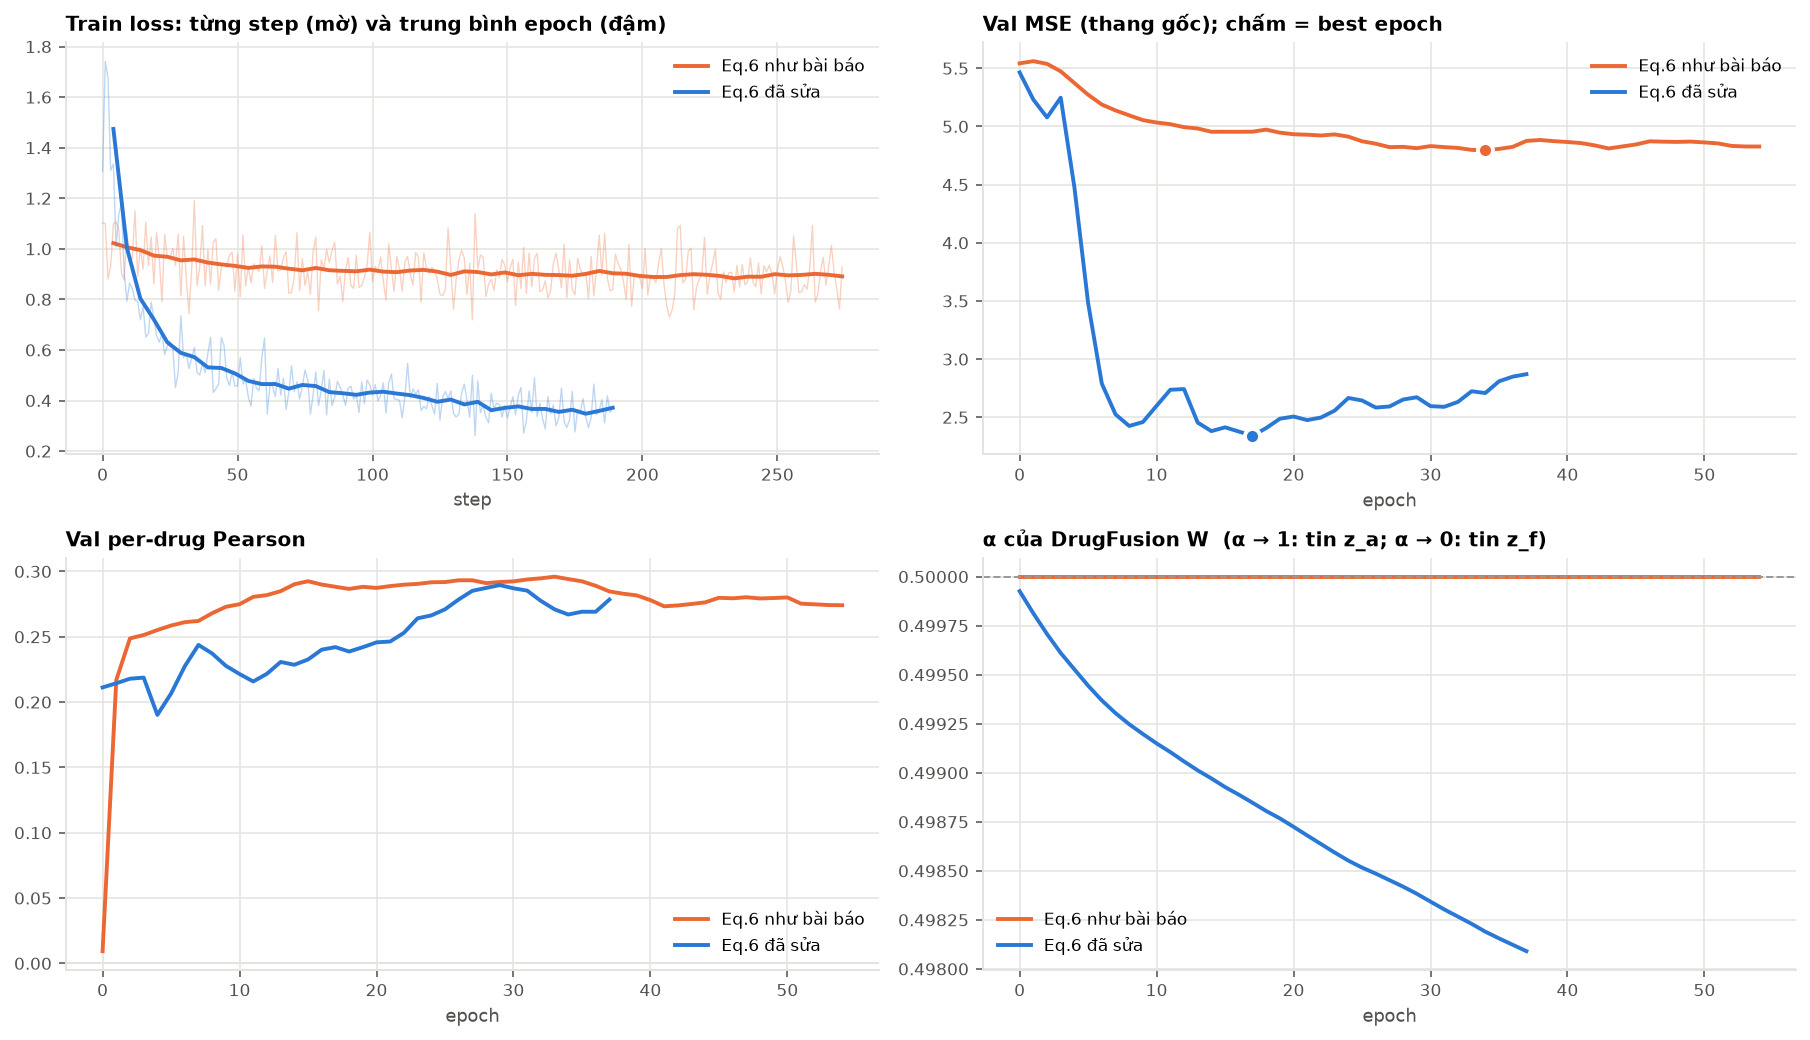

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for label, r in runs.items():
    c, st, ep = VCOLOUR[label], r["steps"], r["epochs"]
    axes[0, 0].plot(st["step"], st["loss"], color=c, lw=0.7, alpha=0.3)
    pe = st.groupby("epoch").agg(step=("step", "max"), loss=("loss", "mean"))
    axes[0, 0].plot(pe["step"], pe["loss"], color=c, lw=2, label=label)
    axes[0, 1].plot(ep["epoch"], ep["val_mse"], color=c, lw=2, label=label)
    axes[0, 1].scatter([r["best_epoch"]], [ep.loc[r["best_epoch"], "val_mse"]], s=60, color=c,
                       edgecolors="white", linewidths=2, zorder=3)
    axes[1, 0].plot(ep["epoch"], ep["val_pc_drug"], color=c, lw=2, label=label)
    axes[1, 1].plot(ep["epoch"], ep["alpha"], color=c, lw=2, label=label)

axes[0, 0].set_title("Train loss: từng step (mờ) và trung bình epoch (đậm)", loc="left")
axes[0, 0].set_xlabel("step")
axes[0, 1].set_title("Val MSE (thang gốc); chấm = best epoch", loc="left")
axes[1, 0].set_title("Val per-drug Pearson", loc="left")
axes[1, 0].axhline(0, color=GRID, lw=1)
axes[1, 1].axhline(0.5, color=NEUTRAL, lw=1, ls="--")
axes[1, 1].set_title("α của DrugFusion W  (α → 1: tin z_a; α → 0: tin z_f)", loc="left")
for ax in axes.flat[1:]:
    ax.set_xlabel("epoch")
for ax in axes.flat:
    ax.legend(loc="best")
plt.tight_layout()
plt.show()

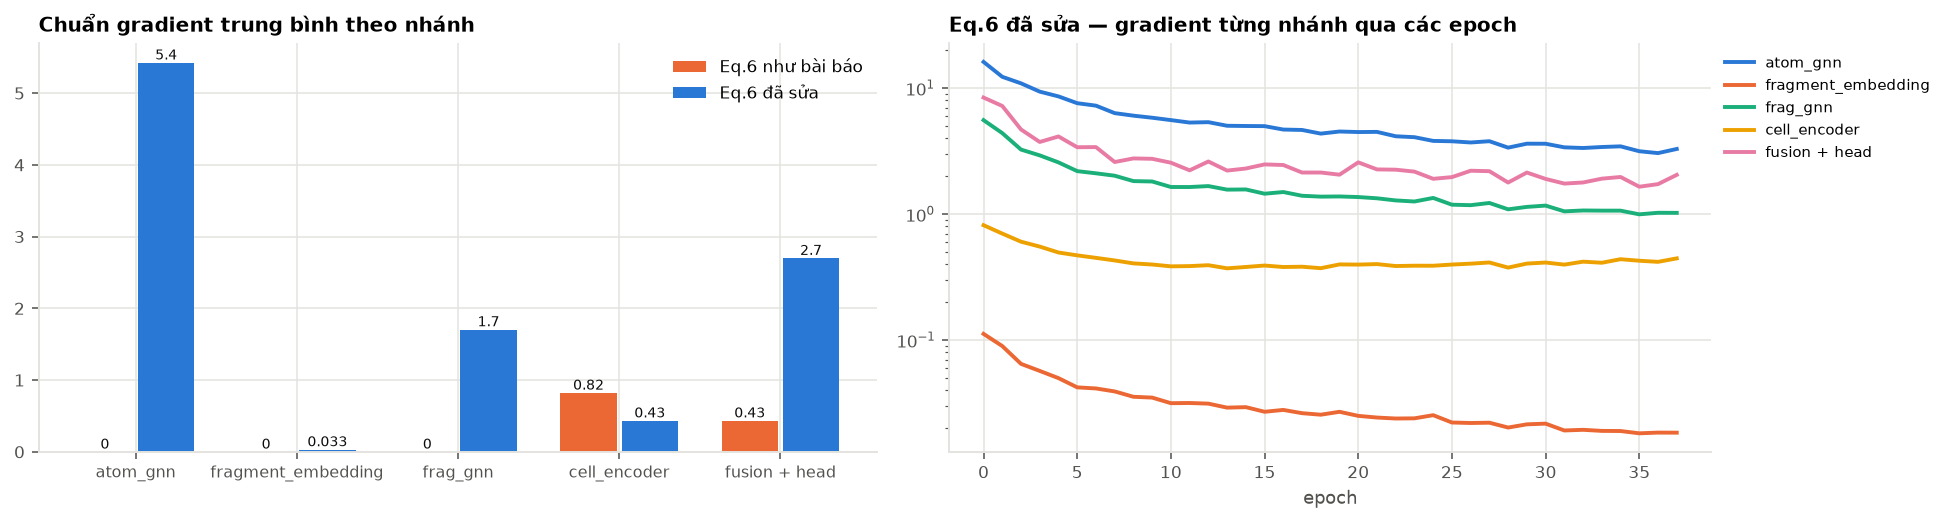

Eq.6 như bài báo   | gradient lớn nhất về nhánh thuốc = 0 | α tại best epoch = 0.500
Eq.6 đã sửa        | gradient lớn nhất về nhánh thuốc = 16.2 | α tại best epoch = 0.499


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
xb = np.arange(len(BRANCHES)); w = 0.38
for j, (label, r) in enumerate(runs.items()):
    vals = [r["epochs"][f"grad_{b}"].mean() for b in BRANCHES]
    ax.bar(xb + (j - 0.5) * w, vals, w - 0.03, color=VCOLOUR[label], label=label)
    for xi, v in zip(xb + (j - 0.5) * w, vals):
        ax.text(xi, v, f"{v:.2g}", ha="center", va="bottom", fontsize=7, color=INK)
ax.set_xticks(xb, BRANCHES, fontsize=8)
ax.set_title("Chuẩn gradient trung bình theo nhánh", loc="left")
ax.legend(loc="upper right")

ax = axes[1]
ep = runs["Eq.6 đã sửa"]["epochs"]
for i, b in enumerate(BRANCHES):
    ax.plot(ep["epoch"], ep[f"grad_{b}"], color=FRAGMENT_COLOURS[i], lw=2, label=b)
ax.set_yscale("log"); ax.set_xlabel("epoch")
ax.set_title("Eq.6 đã sửa — gradient từng nhánh qua các epoch", loc="left")
ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

for label, r in runs.items():
    ep = r["epochs"]
    drug_grad = ep[["grad_atom_gnn", "grad_fragment_embedding", "grad_frag_gnn"]].to_numpy().max()
    print(f"{label:18s} | gradient lớn nhất về nhánh thuốc = {drug_grad:.3g} | "
          f"α tại best epoch = {ep.loc[r['best_epoch'], 'alpha']:.3f}")

## 12. Đánh giá trên fold test

Dưới LDO, metric chính là **per-drug Pearson** (`partial_correlation_drug`): với một thuốc
chưa từng thấy, mô hình có xếp hạng đúng các cell line nhạy/kháng không?

Mốc cần vượt là **baseline cell-line mean**: dự đoán cho cặp (d, c) bằng response trung
bình của cell line c trên tập train — không nhìn phân tử chút nào.

In [31]:
outs = {label: predict(r["model"], loaders["test"]) for label, r in runs.items()}
ref = next(iter(outs.values()))
train_df = frame.iloc[fold.train]
cell_mean = train_df.groupby("cell_line_id")["response"].mean()
base_pred = pd.Series(ref["cell_line_ids"]).map(cell_mean).fillna(train_df["response"].mean()).values

test_df = pd.DataFrame({"drug": ref["drug_ids"], "cell": ref["cell_line_ids"], "y": ref["targets"],
                        "cell-line mean": base_pred,
                        **{label: o["predictions"] for label, o in outs.items()}})
columns = list(outs) + ["cell-line mean"]
keys = ["rmse", "pearson", "spearman", "r2", "partial_correlation_drug", "spearman_per_drug"]
print("metric chính:", primary_metric(cfg["data"]["test_mode"]))
display(pd.DataFrame({c: [compute_metrics(test_df.y, test_df[c], test_df.drug, test_df.cell)[k] for k in keys]
                      for c in columns}, index=keys).round(4))

# Nếu nhánh thuốc chết, dự đoán cho một cell line không phụ thuộc vào thuốc.
for label in outs:
    spread = test_df.groupby("cell")[label].std().max()
    print(f"{label:18s} | độ lệch chuẩn lớn nhất của dự đoán giữa các thuốc, cùng một cell line = {spread:.2e}")

metric chính: partial_correlation_drug


,Eq.6 như bài báo,Eq.6 đã sửa,cell-line mean
rmse,2.6322,2.9545,2.6206
pearson,0.1488,0.1027,0.1803
spearman,0.2182,0.0515,0.2389
r2,-0.0701,-0.3481,-0.0606
partial_correlation_drug,0.3211,0.3449,0.3228
spearman_per_drug,0.3415,0.3557,0.3370


Eq.6 như bài báo   | độ lệch chuẩn lớn nhất của dự đoán giữa các thuốc, cùng một cell line = 0.00e+00
Eq.6 đã sửa        | độ lệch chuẩn lớn nhất của dự đoán giữa các thuốc, cùng một cell line = 2.97e+00


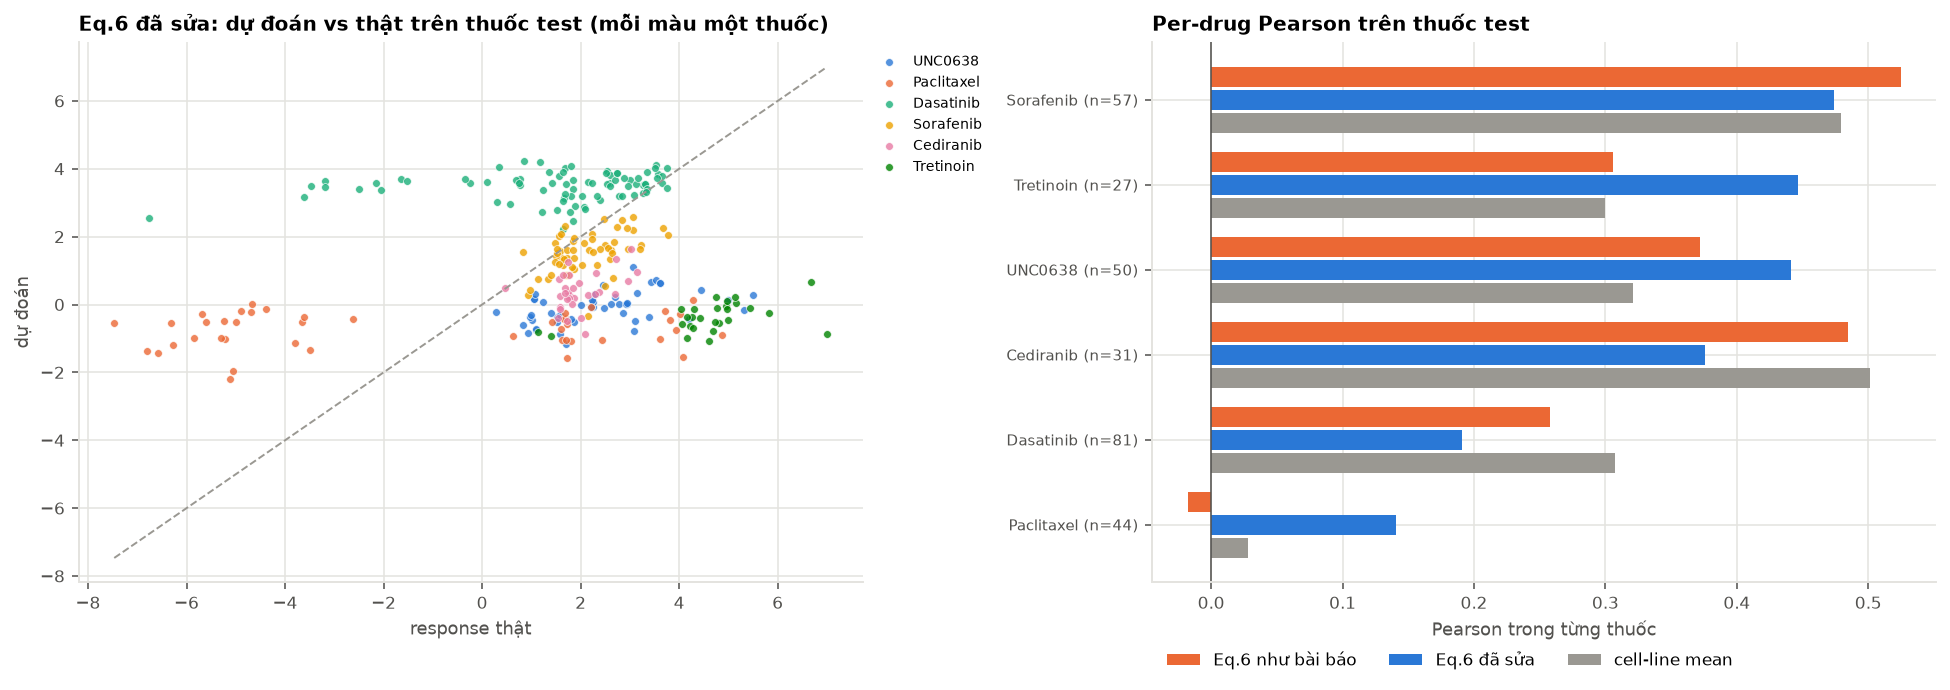

In [32]:
test_drugs = list(test_df["drug"].unique())
per_drug = test_df.groupby("drug").apply(
    lambda d: pd.Series({**{c: np.corrcoef(d.y, d[c])[0, 1] for c in columns}, "n": len(d)}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
shown = "Eq.6 đã sửa"
colour_of = {d: FRAGMENT_COLOURS[i] if len(test_drugs) <= len(FRAGMENT_COLOURS) else BLUE
             for i, d in enumerate(test_drugs)}
for d in test_drugs:
    sub = test_df[test_df.drug == d]
    ax.scatter(sub.y, sub[shown], s=16, color=colour_of[d], alpha=0.8, edgecolors="white",
               linewidths=0.4, label=names.get(d, d)[:20])
lo, hi = test_df[["y", shown]].min().min(), test_df[["y", shown]].max().max()
ax.plot([lo, hi], [lo, hi], color=NEUTRAL, lw=1, ls="--")
ax.set_xlabel("response thật"); ax.set_ylabel("dự đoán")
ax.set_title(f"{shown}: dự đoán vs thật trên thuốc test (mỗi màu một thuốc)", loc="left")
if len(test_drugs) <= len(FRAGMENT_COLOURS):
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))

ax = axes[1]
order_d = per_drug.sort_values(shown).index
yy = np.arange(len(order_d)); h = 0.27
for j, (c, col) in enumerate(zip(columns, [VCOLOUR[k] for k in outs] + [NEUTRAL])):
    ax.barh(yy + (1 - j) * h, per_drug.loc[order_d, c], h - 0.03, color=col, label=c)
ax.set_yticks(yy, [f"{names.get(d, d)[:20]} (n={int(per_drug.loc[d, 'n'])})" for d in order_d], fontsize=7.5)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("Pearson trong từng thuốc")
ax.set_title("Per-drug Pearson trên thuốc test", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=3)
plt.tight_layout()
plt.show()

## 13. Nhìn vào bảng embedding mảnh sau huấn luyện

Một hàng embedding chỉ nhận gradient khi mảnh đó xuất hiện trong **thuốc train**. Với Adam
và `weight_decay = 0`, hàng không bao giờ nhận gradient sẽ **giữ nguyên giá trị khởi tạo
ngẫu nhiên**. Dưới LDO, mảnh chỉ có trong thuốc test rơi đúng vào trường hợp này — dù chúng
"có trong vocabulary" (coverage 100% ở bước 7). Với biến thể Eq. 6 như bài báo, *không hàng
nào* thay đổi (bước 11).

Eq.6 như bài báo   | thay đổi lớn nhất của một hàng embedding = 0
Eq.6 đã sửa        | thay đổi lớn nhất của một hàng embedding = 0.0163


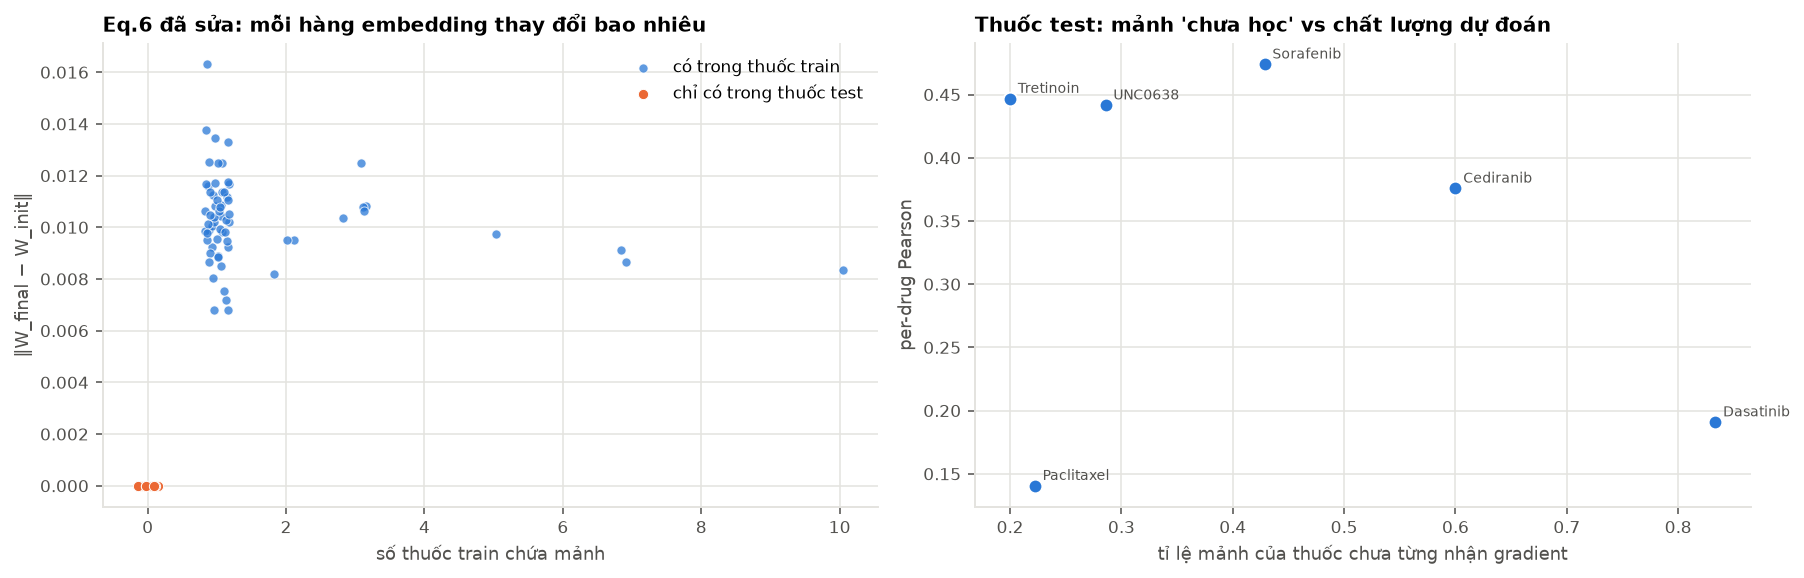

15 / 89 hàng vocabulary chỉ dùng bởi thuốc test; thay đổi lớn nhất của chúng = 0.00e+00
708 hàng dư (vocab_size 798 > số mảnh) không bao giờ dùng


In [33]:
train_drug_set = set(data.drug_ids[fold.train]) & set(drug_graphs)
n_train_drugs = Counter()
for d in train_drug_set:
    n_train_drugs.update(set(drug_graphs[d].frag_vocab_ids.tolist()))
test_ids = set()
for d in test_drugs:
    test_ids.update(drug_graphs[d].frag_vocab_ids.tolist())
ids_in_vocab = np.array(sorted(vocabulary.index_of.values()))
x = np.array([n_train_drugs[i] for i in ids_in_vocab])
only_test = np.array([(n_train_drugs[i] == 0) and (i in test_ids) for i in ids_in_vocab])

deltas = {}
for label, r in runs.items():
    W = r["model"].fragment_embedding.weight.detach().float().cpu()
    deltas[label] = (W - r["emb_init"]).norm(dim=1).numpy()
    print(f"{label:18s} | thay đổi lớn nhất của một hàng embedding = {deltas[label].max():.3g}")

label = "Eq.6 đã sửa"
y = deltas[label][ids_in_vocab]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
jit = x + rng.uniform(-0.18, 0.18, len(x))
ax.scatter(jit[~only_test], y[~only_test], s=22, color=BLUE, alpha=0.75, edgecolors="white",
           linewidths=0.5, label="có trong thuốc train")
ax.scatter(jit[only_test], y[only_test], s=28, color=ORANGE, edgecolors="white", linewidths=0.5,
           label="chỉ có trong thuốc test")
ax.set_xlabel("số thuốc train chứa mảnh"); ax.set_ylabel("‖W_final − W_init‖")
ax.set_title(f"{label}: mỗi hàng embedding thay đổi bao nhiêu", loc="left")
ax.legend()

ax = axes[1]
frac_untrained = {d: np.mean([n_train_drugs[i] == 0 for i in drug_graphs[d].frag_vocab_ids.tolist()])
                  for d in per_drug.index}
xs = np.array([frac_untrained[d] for d in per_drug.index])
ax.scatter(xs, per_drug[label], s=50, color=BLUE, edgecolors="white", linewidths=1)
for d, xv, yv in zip(per_drug.index, xs, per_drug[label]):
    ax.annotate(names.get(d, d)[:14], (xv, yv), xytext=(4, 3), textcoords="offset points",
                fontsize=7, color=MUTED)
ax.set_xlabel("tỉ lệ mảnh của thuốc chưa từng nhận gradient"); ax.set_ylabel("per-drug Pearson")
ax.set_title("Thuốc test: mảnh 'chưa học' vs chất lượng dự đoán", loc="left")
plt.tight_layout()
plt.show()

print(f"{only_test.sum()} / {len(ids_in_vocab)} hàng vocabulary chỉ dùng bởi thuốc test; "
      f"thay đổi lớn nhất của chúng = {y[only_test].max() if only_test.any() else 0:.2e}")
print(f"{vocabulary.size - len(ids_in_vocab) - 1} hàng dư (vocab_size {vocabulary.size} > số mảnh) không bao giờ dùng")

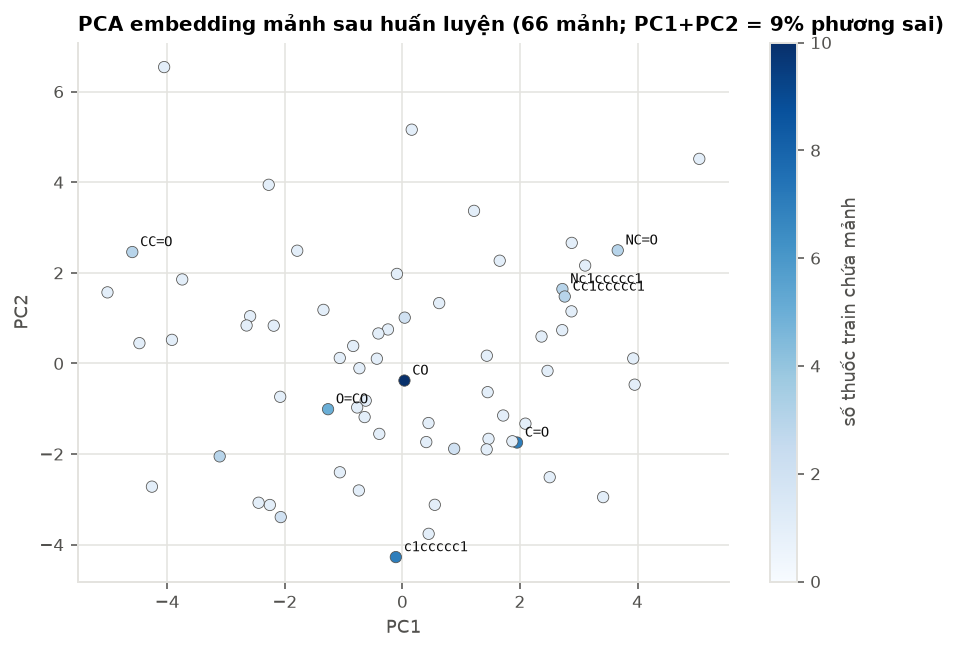

In [34]:
# PCA 2D của các hàng embedding đã học (chỉ những mảnh có trong thuốc train)
trained = ids_in_vocab[x > 0]
E = runs["Eq.6 đã sửa"]["model"].fragment_embedding.weight.detach().float().cpu()[trained].numpy()
E = E - E.mean(0)
U, s_, Vt = np.linalg.svd(E, full_matrices=False)
P = E @ Vt[:2].T
freq_tr = np.array([n_train_drugs[i] for i in trained])

fig, ax = plt.subplots(figsize=(7.5, 5))
sc = ax.scatter(P[:, 0], P[:, 1], c=freq_tr, cmap=SEQ, s=34, edgecolors=MUTED, linewidths=0.4,
                vmin=0, vmax=max(freq_tr.max(), 2))
fig.colorbar(sc, ax=ax, label="số thuốc train chứa mảnh")
inv = {i: s for s, i in vocabulary.index_of.items()}
for j in np.argsort(-freq_tr)[:8]:
    ax.annotate(inv[trained[j]][:22], P[j], xytext=(4, 3), textcoords="offset points",
                fontsize=7, color=INK, family="DejaVu Sans Mono")
ax.set_title(f"PCA embedding mảnh sau huấn luyện ({len(trained)} mảnh; "
             f"PC1+PC2 = {(s_[:2] ** 2).sum() / (s_ ** 2).sum():.0%} phương sai)", loc="left")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.show()

## 14. Chạy tất cả các fold bằng `train.run_fold`

Đây chính là hàm mà `python train.py` gọi (còn `--fix-attention` chỉ bật
`fix_degenerate_attention`). Với TOYv1 mất khoảng một phút cho cả hai biến thể; với GDSC2
mỗi fold có thể mất rất lâu, nên mặc định chỉ bật khi `DATASET == "TOYv1"`.

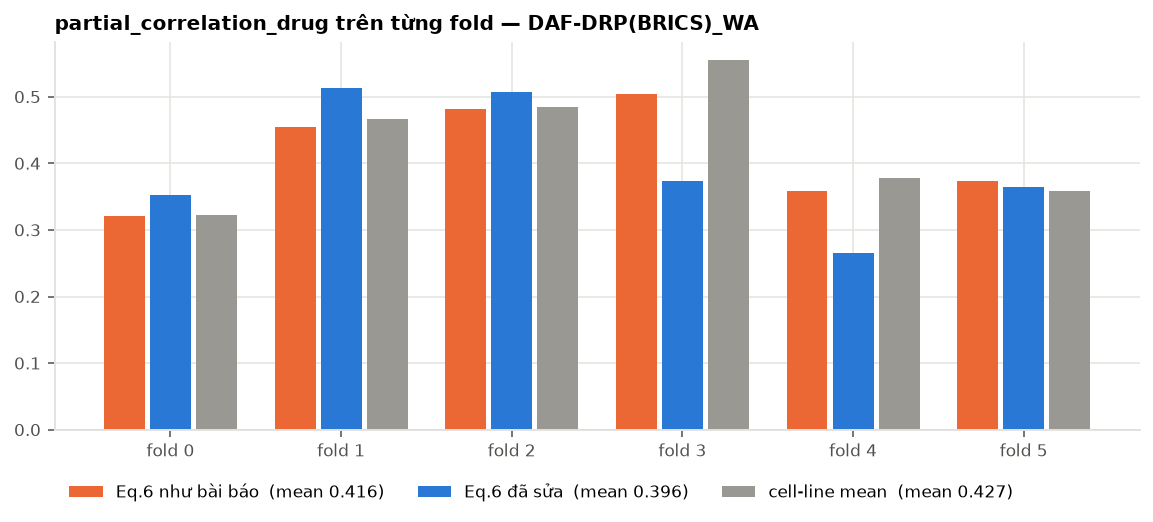

rmse         pearson              r2          \
                    mean     std    mean     std    mean     std   
model                                                              
Eq.6 như bài báo  2.5257  0.5242  0.2589  0.0604 -0.0233  0.1308   
Eq.6 đã sửa       2.7560  0.6997 -0.0001  0.4388 -0.2466  0.3828   
cell-line mean    2.5260  0.5247  0.2768  0.0542 -0.0238  0.1327   

                 partial_correlation_drug          
                                     mean     std  
model                                              
Eq.6 như bài báo                   0.4155  0.0741  
Eq.6 đã sửa                        0.3963  0.0963  
cell-line mean                     0.4274  0.0887

In [35]:
RUN_ALL_FOLDS = DATASET == "TOYv1"

if RUN_ALL_FOLDS:
    logging.getLogger("daf_drp_brics").setLevel(logging.WARNING)   # bớt log từng epoch
    metric = primary_metric(cfg["data"]["test_mode"])
    rows = []
    for label, fix in VARIANTS.items():
        cfg_v = copy.deepcopy(cfg)
        cfg_v["model"]["fix_degenerate_attention"] = fix
        for f in folds:
            o = run_fold(cfg_v, data, f, drug_graphs, int(cfg["model"]["vocab_size"]))
            rows.append({"model": label, "fold": f.index, **o["metrics"]})
    for f in folds:                                   # baseline cell-line mean trên cùng fold
        tr = frame.iloc[f.train]
        te = frame.iloc[f.test]
        pred_b = te["cell_line_id"].map(tr.groupby("cell_line_id")["response"].mean()).fillna(tr["response"].mean())
        rows.append({"model": "cell-line mean", "fold": f.index,
                     **compute_metrics(te["response"], pred_b, te["drug_id"], te["cell_line_id"])})
    all_folds = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(10, 3.6))
    models_ = list(VARIANTS) + ["cell-line mean"]
    cols = [VCOLOUR[m] for m in VARIANTS] + [NEUTRAL]
    w = 0.27
    for j, (m, c) in enumerate(zip(models_, cols)):
        sub = all_folds[all_folds.model == m].sort_values("fold")
        ax.bar(sub["fold"] + (j - 1) * w, sub[metric], w - 0.03, color=c,
               label=f"{m}  (mean {sub[metric].mean():.3f})")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xticks(range(len(folds)), [f"fold {i}" for i in range(len(folds))])
    ax.set_title(f"{metric} trên từng fold — DAF-DRP(BRICS)_{mcfg['drug_fusion']}{mcfg['global_fusion']}",
                 loc="left")
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=3)
    plt.show()
    summary_cols = ["rmse", "pearson", "r2", "partial_correlation_drug"]
    display(all_folds.groupby("model")[summary_cols].agg(["mean", "std"]).round(4))

In [36]:
# Kết quả đã chạy trước đó bằng train.py (nếu có) để đối chiếu
rows = []
for run_dir in sorted((HERE / "results").glob("dafbrics_*")):
    csv = run_dir / "per_fold_metrics.csv"
    if csv.exists():
        pf = pd.read_csv(csv)
        rows.append({"run": run_dir.name, "folds": len(pf),
                     **{f"{c}": f"{pf[c].mean():.3f} ± {pf[c].std(ddof=1):.3f}"
                        for c in ("rmse", "pearson", "partial_correlation_drug") if c in pf}})
pd.DataFrame(rows)

,run,folds,rmse,pearson,partial_correlation_drug
0,dafbrics_CC_TOYv1_LDO,2,2.566 ± 0.172,0.173 ± 0.068,0.234 ± 0.037
1,dafbrics_WA-fixattn_GDSC2_LDO,6,2.491 ± 0.328,0.381 ± 0.137,0.306 ± 0.025
2,dafbrics_WA_GDSC2_LDO,6,2.536 ± 0.305,0.175 ± 0.041,0.300 ± 0.012
3,dafbrics_WA_TOYv1_LDO,2,2.610 ± 0.160,0.158 ± 0.051,0.286 ± 0.048


## Tóm tắt

* **Atom → Fragment** là một phép chia tập nguyên tử (ma trận $S$). BRICS quyết định *cắt
  liên kết nào*; các mảnh là thành phần liên thông sau khi cắt, rồi mảnh nhỏ được gộp.
  Đồ thị mảnh $A_f = [S^\top A_a S > 0]$ đúng bằng các junction bond.
* Nhánh fragment chỉ nhận **chỉ số vocabulary** → một bảng embedding tra cứu. Nó không biết
  mảnh gồm nguyên tử nào; hai encoder độc lập hoàn toàn cho tới bước fusion.
* **Eq. 6 như được in trong bài báo không chỉ suy biến thành $bW_V$ mà còn chặn gradient về
  query.** Trong WA (và CA, AA), query của GlobalFusion là $z_{drug}$, nên atom GNN, bảng
  embedding và fragment GNN **không bao giờ được huấn luyện**; dự đoán chỉ phụ thuộc vào cell
  line và vì vậy không thể tốt hơn baseline cell-line mean một cách có hệ thống. Với AC/AA,
  DrugFusion = A thì $O(z_a, z_f) = z_f W_V$ và nhánh atom bị chặn theo cùng cách.
* Sửa Eq. 6 (`--fix-attention`) mở lại gradient cho nhánh thuốc và làm val MSE giảm mạnh
  (mô hình học được mức potency trung bình của từng thuốc), nhưng trên TOYv1 — chỉ ~24 thuốc
  train mỗi fold — per-drug Pearson vẫn **không vượt** baseline cell-line mean (bước 14). Đây là
  kết quả trên dữ liệu đồ chơi; chạy lại với `DATASET = "GDSC2"` để có kết luận thật.
* Kể cả khi đã sửa Eq. 6, phần lớn mảnh BRICS chỉ xuất hiện một lần, nên dưới LDO nhiều hàng
  embedding của thuốc test **chưa từng được huấn luyện** (bước 13), dù coverage vocabulary
  là 100%.